[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/VQC_AdversarialConcentration_Liu2020.ipynb)

# Concentration of measure and adversarial perturbations of quantum classifiers: Liu and Wittek (2020), checked numerically, step by step

**Paper.** Nana Liu and Peter Wittek, *Vulnerability of quantum classification to adversarial perturbations*,
Physical Review A **101**, 062331 (2020), arXiv:1905.04286, DOI 10.1103/PhysRevA.101.062331.

**The paper's results are analytic, not experimental.** The paper contains no dataset, no trained model and no table of accuracies.
It proves (via Levy's lemma / concentration of measure on the unitary group) that for almost every Haar-random input, a
perturbation whose Hilbert-Schmidt size shrinks like `d^(-1/2)` (`d = 2^n`) is enough to make *any* quantum classifier misclassify,
translates this into a fidelity bound `1 - F <= g / d^2`, and concludes that certifying the input needs at least `d^4` copies.
**This notebook verifies those statements numerically** on exact state-vector simulations: it measures, for Haar-random inputs
on `n = 2 ... 10` qubits, the exact distance to the nearest adversarial example of fixed and trained variational classifiers,
checks the concentration bound on every instance, fits the scaling exponents, repeats the measurement for a classical linear model
on identical inputs, and contrasts everything with real MNIST digits amplitude-encoded into the same qubits.
Each claim of the paper receives an explicit verdict (bound holds / violated, exponent reproduced / not reproduced).

**How to run.** Open in Google Colab (CPU runtime is enough), `Runtime -> Run all`. With `FAST_MODE = True` (default)
the notebook finishes in roughly 15 to 30 minutes on a (busy) CPU; the full budgets are listed in the configuration cell.
Everything is seeded (`SEED = 42`). No account, API key or quantum hardware is needed; the one real dataset (MNIST, digits 0 and 1)
is downloaded from the public Hugging Face mirror `ylecun/mnist`.

**What you get at the end.** (i) a validated exact simulator checked against Qiskit; (ii) three attacks (closed-form optimum,
exact-gradient iterative attack, first-order margin attack) and a brute-force check that agree; (iii) scaling plots of the
nearest-adversarial distance versus qubit number; (iv) a table of per-claim verdicts for the paper; (v) a critical reading and exercises.

## The paper in one page

**Problem.** Alice classifies a `d`-dimensional pure state `sigma = U|b><b|U^dagger` (an `n = log2 d` qubit state), `U` Haar-random.
Her device applies a CPTP map and measures an observable `O`; the real output `v(sigma) = Tr(O Lambda(sigma))` is turned into a label
`h(sigma) = sign v(sigma)`. A ground-truth labelling `c` exists; `M = {sigma : h(sigma) != c(sigma)}` is the misclassified set and
`mu(M) > 0` its Haar measure (the *risk*). Bob may replace `sigma` by a nearby `rho` that Alice cannot certify to be different.

**Decision / claims.**
1. *Theorem 1 (Eq. 3 / B8).* With the Hilbert-Schmidt metric `H` on `SU(d)` (a `(sqrt 2, 1/4)`-normal Levy family),
   if the adversarial risk is to stay below `R` the perturbation must satisfy `H^2 < (4/d) ln( 2 / (mu(M) (1 - R)) )`.
   In words: for large `d` a perturbation of size `O(d^(-1/2))` already reaches a misclassified state with probability at least `R`.
   (The extracted text of Eq. 3 prints "4d ln"; the proof, Eq. B4 with `l1 = sqrt 2`, `l2 = 1/4`, gives `4/d`. We use `4/d`.)
2. *Eq. C3/C4.* Using `H^2 >= 2d (1 - F)` for `psi_i = u_i|b>`, the bound becomes a fidelity statement:
   `F(psi_1, psi_2) >= 1 - g/d^2` with `g = 2 ln(2/(mu(M)(1-R)))`, i.e. an infidelity of order `d^(-2)` suffices.
3. *Theorem 2a / 2b.* Certifying the state (or the device) to the precision `eta < g/d^2` needs `N >= d^4 / (g^2 Delta)` copies (calls).
4. *Appendix A.* For `O >= 0`: `|v(sigma) - v(rho)| < 2 sqrt 2 Tr(O) sqrt(chi)` when `F(sigma, rho) >= 1 - chi`, so for ordinary (continuous) outputs
   small perturbations are harmless; classification is different because labels flip at a boundary.
5. *Qualitative claim.* The effect comes from the geometry of high-dimensional spaces and is independent of the details of the classification protocol.

**Data / preprocessing.** None: inputs are Haar-random states, labels come from an abstract `c`.
**Reported numbers.** None: all statements are analytic scalings (`H^2 ~ 1/d`, `1 - F ~ 1/d^2`, `N ~ d^4`).

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Inputs | `sigma = U|b>`, `U` Haar on `SU(d)` | Haar-random pure states on `n = 2..10` qubits (normalised complex Gaussian vectors) |
| Device | any CPTP map `Lambda` and observable `O` | CHOICE: unitary VQC `U(theta)` (RY layers + CX chain, `L = 2`) followed by a projective `Z` measurement on qubit 0, `h = sign <Z_0>` |
| Ground truth `c` | an arbitrary function, "not directly accessible" | CHOICE: a *teacher* circuit of the same family with random angles (`SIGMA_T`); `c(psi) = sign <psi|O_T|psi>` |
| Hypothesis `h` | any `h` with `mu(M) > 0` | CHOICE: (a) *fixed* = teacher angles plus Gaussian noise, (b) *trained* = VQC trained by Adam with exact gradients on `N_TRAIN` labelled Haar states |
| Distance `H` | Hilbert-Schmidt distance of unitaries (Eq. C1) | the minimal HS distance between two unitary lifts of the states, which equals `2 sqrt(1 - F)` (proved and checked numerically below) |
| Fidelity `F` | `|<psi_1|psi_2>|` | same (amplitude fidelity) |
| Adversary | Bob may prepare any state | unrestricted state perturbation; closed-form optimum, iterative exact-gradient attack, first-order margin attack, brute-force optimiser |
| Levy constants | `(sqrt 2, 1/4)` | taken from the paper; the rigorous two-step version `eps = eps_1 + eps_2` of the cited Theorem 3.7 is tested as well |
| Risk `R` | upper bound on adversarial risk | `gamma = 1 - R in {0.5, 0.2, 0.05}`; `mu(M)` estimated on an independent Haar sample |
| Qubits | arbitrary `d` | `n = 2..10` (`d = 4..1024`), exact state-vector simulation (an RY/CX circuit is a real orthogonal matrix, so it is applied to real and imaginary parts separately) |
| Classical model | not in the paper | CHOICE: logistic regression on `[Re psi, Im psi]` (identical inputs) with a closed-form nearest-flip distance on the unit sphere |
| Low-dimensional data | not in the paper | CHOICE (requested contrast): real MNIST digits 0 and 1, resized to `2^n` pixels and amplitude-encoded, classified by the same VQC family |
| Certification cost (Thm 2a/2b) | `N >= d^4/(g^2 Delta)` | arithmetic consequence of the measured fidelity scaling only; the certification protocols themselves are not simulated |

Choices are marked `# CHOICE:` in the code.

In [1]:
# ------------------------------------------------------------------ installs (pinned to the versions this notebook was tested with)
import sys, importlib, subprocess, os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
IN_COLAB = "google.colab" in sys.modules
def _have(mod):
    try:
        importlib.import_module(mod); return True
    except Exception:
        return False
need = []
if IN_COLAB or not _have("qiskit"):
    need += ["qiskit==2.5.2"]
if IN_COLAB or not _have("pylatexenc"):
    need += ["pylatexenc"]
for mod, pkg in [("huggingface_hub", "huggingface_hub"), ("pyarrow", "pyarrow"), ("PIL", "pillow")]:
    if not _have(mod):
        need.append(pkg)
if need:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install"] + need, check=True)
    print("installed:", need, "(restart the runtime if an import below fails)")
else:
    print("all packages already available")

all packages already available


In [2]:
# ------------------------------------------------------------------ configuration (every tunable constant lives here)
SEED = 42
FAST_MODE = True            # True: class demo (about 10-25 min on a CPU).  False: full budgets below (about 1 h on a CPU)
DATA_DIR = "qc342_data"     # MNIST parquet files are cached here
IBM_TOKEN = ""              # unused: everything is an exact classical simulation, no hardware needed
THREADS = 1                 # BLAS threads (raise on a quiet multi-core machine)

def pick(fast, full):
    return fast if FAST_MODE else full

NS          = list(range(2, 11))        # qubit numbers n (dimension d = 2**n)
N_LAYERS    = 2                         # entangling layers L of the VQC (parameters = n (L + 1))
N_SEEDS     = pick(2, 3)                # independent teachers / students per n
N_TRAIN     = pick(300, 600)            # labelled Haar states available for training the student
BATCH       = pick(48, 96)              # mini-batch per Adam step
TRAIN_STEPS = pick(60, 120)
LR          = 0.1
SIGMA_T     = 0.3                       # std of the teacher angles (ground truth c)
SIGMA_FIXED = 0.2                       # std of the noise added to the teacher angles for the "fixed" classifier
N_TEST      = pick(1000, 3000)          # Haar states for the distance statistics (and the same number again for mu(M))
GAMMAS      = [0.5, 0.2, 0.05]          # gamma = 1 - R
N_ATTACK_CHECK = pick(100, 300)         # states per n for the attack validation
N_FIT_MIN   = 3                         # smallest n used for scaling fits (d >= 8)
# MNIST contrast
MNIST_PAIR  = (0, 1)
MNIST_TRAIN_PER_CLASS = pick(150, 400)
MNIST_TEST_PER_CLASS  = pick(250, 500)
MNIST_STEPS = pick(60, 120)
MNIST_BETA  = 4.0                       # logit scale for the MNIST classifier (outputs are not concentrated there)
print("FAST_MODE =", FAST_MODE, "| qubits", NS[0], "..", NS[-1], "| seeds", N_SEEDS, "| N_TEST", N_TEST)

FAST_MODE = True | qubits 2 .. 10 | seeds 2 | N_TEST 1000


In [3]:
import os, time, io, math, warnings
for _k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[_k] = str(THREADS)
import numpy as np, pandas as pd, scipy, sklearn
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, SparsePauliOp
from PIL import Image
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
os.makedirs(DATA_DIR, exist_ok=True)
rng_global = np.random.default_rng(SEED)
print("numpy", np.__version__, "| scipy", scipy.__version__, "| sklearn", sklearn.__version__, "| qiskit", qiskit.__version__,
      "| matplotlib", matplotlib.__version__, "| pandas", pd.__version__)

# Hugging Face token: only needed for gated datasets; the MNIST mirror used here is public, so None works.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
print("HF token available:", HF_TOKEN is not None)

numpy 2.5.4 | scipy 1.18.1 | sklearn 1.9.1 | qiskit 2.5.2 | matplotlib 3.11.2 | pandas 3.0.6
HF token available: True


## 1. An exact simulator for the classifier, checked against Qiskit

**The classifier.** The classification device of the paper is a unitary followed by a measurement. We use a hardware-efficient
variational circuit on `n` qubits: `L` layers of `RY(theta)` on every qubit followed by a chain of CX gates (`q+1 -> q`), then one more
RY layer, then a projective measurement of `Z` on qubit 0. The label is `h(psi) = sign <psi| U^T Z_0 U |psi>`.

**Why a custom simulator.** All gates are real (RY and CX), so `U` is a real orthogonal matrix: we apply it to the real and imaginary
parts of a whole batch of states with a few NumPy operations, and we get exact reverse-mode gradients for training. Because this
simulator replaces the Qiskit circuit in the large experiments, the next cell **asserts that it reproduces Qiskit's `Statevector`
evolution and `Z_0` expectation values** to `1e-10` for several sizes, and that the analytic gradient matches finite differences.

**Exact adversarial distance for a projective classifier (derivation used below).** In the eigenbasis of `O = U^T Z_0 U`
(eigenvalues `+1` and `-1`) write `psi = sqrt(p+) |a> + sqrt(p-) |b>` with `v = p+ - p-`. The closest state on the decision boundary
`p+ = p- = 1/2` keeps the directions `|a>`, `|b>` and rescales the two weights, so its fidelity with `psi` is
`F_flip = (sqrt(p+) + sqrt(p-)) / sqrt 2 = ( sqrt(1+v) + sqrt(1-v) ) / 2`. The distance of the paper (Hilbert-Schmidt distance of the
unitary lifts, Eq. C1) is then `H = 2 sqrt(1 - F)` (checked with explicit unitaries in section 7).
For small `|v|`, `1 - F ~ v^2 / 8`, and for Haar inputs `v` has standard deviation `~ 1/sqrt(d)`: this already predicts
`H^2 ~ 1/d` and `1 - F ~ 1/d` (not `1/d^2`). The numerical sections below test this prediction against the paper's statements.

In [4]:
# ---------------------------------------------------------------- circuit description (shared by simulator and Qiskit)
def gate_list(n, L):
    """Hardware-efficient ansatz: L x [RY on every qubit, CX chain (q+1 -> q)], then a final RY layer."""
    seq, k = [], 0
    for _ in range(L):
        for q in range(n):
            seq.append(("ry", q, k)); k += 1
        for q in range(n - 1):
            seq.append(("cx", q + 1, q))
    for q in range(n):
        seq.append(("ry", q, k)); k += 1
    return seq

def n_params(n, L):
    return n * (L + 1)

_PERM = {}
def _perm(n, c, t):
    key = (n, c, t)
    if key not in _PERM:
        idx = np.arange(1 << n)
        _PERM[key] = idx ^ (((idx >> c) & 1) << t)      # CX is an involution: new[i] = old[perm[i]]
    return _PERM[key]

def _ry(X, n, q, th):
    B, d = X.shape
    lo = 1 << q
    Y = X.reshape(B, d // (2 * lo), 2, lo)
    c, s = np.cos(th / 2), np.sin(th / 2)
    out = np.empty_like(Y)
    out[:, :, 0, :] = c * Y[:, :, 0, :] - s * Y[:, :, 1, :]
    out[:, :, 1, :] = s * Y[:, :, 0, :] + c * Y[:, :, 1, :]
    return out.reshape(B, d)

def apply_U(theta, n, L, X):
    """Apply the (real orthogonal) ansatz unitary to the rows of X (qubit q = bit q, Qiskit little endian)."""
    for kind, a, b in gate_list(n, L):
        X = _ry(X, n, a, theta[b]) if kind == "ry" else X[:, _perm(n, a, b)]
    return X

def apply_Ut(theta, n, L, X):
    for kind, a, b in reversed(gate_list(n, L)):
        X = _ry(X, n, a, -theta[b]) if kind == "ry" else X[:, _perm(n, a, b)]
    return X

def expect_Z0(theta, n, L, xr, xi):
    """<psi| U^T Z_0 U |psi> for rows psi = xr + i xi (U real)."""
    pr, pi_ = apply_U(theta, n, L, xr), apply_U(theta, n, L, xi)
    prob = pr ** 2 + pi_ ** 2
    return 2 * prob[:, 0::2].sum(1) - 1

def loss_and_grad(theta, n, L, xr, xi, y, beta):
    """Logistic loss of the VQC output beta*<Z_0>, exact gradient by reverse-mode differentiation of the gate list."""
    B, d = xr.shape
    X = np.concatenate([xr, xi], 0)
    cache = []
    seq = gate_list(n, L)
    for kind, a, b in seq:
        if kind == "ry":
            cache.append(X); X = _ry(X, n, a, theta[b])
        else:
            X = X[:, _perm(n, a, b)]
    prob = X[:B] ** 2 + X[B:] ** 2
    v = 2 * prob[:, 0::2].sum(1) - 1
    z = y * beta * v
    loss = np.mean(np.logaddexp(0, -z))
    dLdv = -y * beta / (1 + np.exp(z)) / B
    S = np.ones(d); S[1::2] = -1
    G = 2 * S[None, :] * X * np.concatenate([dLdv, dLdv])[:, None]
    grad = np.zeros_like(theta)
    ci = len(cache)
    for kind, a, b in reversed(seq):
        if kind == "ry":
            ci -= 1
            Xin = cache[ci]
            lo = 1 << a
            Xi_ = Xin.reshape(2 * B, d // (2 * lo), 2, lo)
            Gi_ = G.reshape(2 * B, d // (2 * lo), 2, lo)
            c, s = np.cos(theta[b] / 2), np.sin(theta[b] / 2)
            d0 = -0.5 * s * Xi_[:, :, 0, :] - 0.5 * c * Xi_[:, :, 1, :]
            d1 = 0.5 * c * Xi_[:, :, 0, :] - 0.5 * s * Xi_[:, :, 1, :]
            grad[b] += np.sum(Gi_[:, :, 0, :] * d0 + Gi_[:, :, 1, :] * d1)
            G = _ry(G, n, a, -theta[b])
        else:
            G = G[:, _perm(n, a, b)]
    return loss, grad

def train_vqc(xr, xi, y, n, L, theta0, steps, lr, beta, batch=None, seed=0):
    rng = np.random.default_rng(seed)
    th = theta0.copy(); m = np.zeros_like(th); s2 = np.zeros_like(th)
    N = len(y); hist = []
    for t in range(1, steps + 1):
        if batch is not None and batch < N:
            ii = rng.choice(N, batch, replace=False)
            lo, g = loss_and_grad(th, n, L, xr[ii], xi[ii], y[ii], beta)
        else:
            lo, g = loss_and_grad(th, n, L, xr, xi, y, beta)
        m = 0.9 * m + 0.1 * g; s2 = 0.999 * s2 + 0.001 * g * g
        th = th - lr * (m / (1 - 0.9 ** t)) / (np.sqrt(s2 / (1 - 0.999 ** t)) + 1e-8)
        hist.append(lo)
    return th, np.array(hist)

# ---------------------------------------------------------------- states and geometry
def haar_batch(rng, n, B):
    d = 1 << n
    xr = rng.standard_normal((B, d)); xi = rng.standard_normal((B, d))
    nr = np.sqrt((xr ** 2 + xi ** 2).sum(1, keepdims=True))
    return xr / nr, xi / nr

def flip_fidelity(v):
    """Largest |<psi|psi'>| over states psi' on the decision boundary <Z_0 U>=0, given the output v of psi (closed form)."""
    v = np.clip(v, -1, 1)
    return 0.5 * (np.sqrt(1 + v) + np.sqrt(1 - v))

def hs_dist(F):
    """Smallest Hilbert-Schmidt distance between unitaries u1, u2 with u1|b>=psi1, u2|b>=psi2, |<psi1|psi2>|=F."""
    return 2 * np.sqrt(np.clip(1 - F, 0, None))

def exact_attack_state(theta, n, L, xr, xi, delta=1e-6):
    """Explicit closest adversarial state for the projective classifier sign<U^T Z0 U> (just across the boundary)."""
    pr, pi_ = apply_U(theta, n, L, xr), apply_U(theta, n, L, xi)
    prob = pr ** 2 + pi_ ** 2
    pp = prob[:, 0::2].sum(1); pm = 1 - pp
    v = 2 * pp - 1
    sg = np.where(v >= 0, 1.0, -1.0)
    se = np.sqrt((0.5 - sg * delta) / pp); so = np.sqrt((0.5 + sg * delta) / pm)
    sc = np.empty_like(pr); sc[:, 0::2] = se[:, None]; sc[:, 1::2] = so[:, None]
    return apply_Ut(theta, n, L, pr * sc), apply_Ut(theta, n, L, pi_ * sc)

def deepfool_attack(theta, n, L, xr, xi, eta=0.02, max_it=60, bis=30):
    """Iterative gradient attack with the exact gradient of v(psi)=<psi|O|psi>; returns the first-order (margin) step, final adversarial states."""
    B, d = xr.shape
    S = np.ones(d); S[1::2] = -1
    def v_and_grad(ar, ai):
        pr, pi_ = apply_U(theta, n, L, ar), apply_U(theta, n, L, ai)
        v = ((pr ** 2 + pi_ ** 2) * S).sum(1)
        gr = apply_Ut(theta, n, L, S * pr); gi = apply_Ut(theta, n, L, S * pi_)      # O psi
        gr = 2 * (gr - v[:, None] * ar); gi = 2 * (gi - v[:, None] * ai)             # tangent gradient
        return v, gr, gi
    v0, g0r, g0i = v_and_grad(xr, xi)
    sgn = np.where(v0 >= 0, 1.0, -1.0)
    gn2 = (g0r ** 2 + g0i ** 2).sum(1)
    margin_step = np.abs(v0) / np.sqrt(gn2)                    # first-order (DeepFool) distance, Euclidean length of the tangent step
    ar, ai = xr.copy(), xi.copy()
    done = np.zeros(B, bool)
    for _ in range(max_it):
        v, gr, gi = v_and_grad(ar, ai)
        done = (np.sign(v) != sgn) & (v != 0)
        if done.all(): break
        gn = (gr ** 2 + gi ** 2).sum(1)
        stp = (v / gn * (1 + eta))[:, None]
        nr_, ni_ = ar - stp * gr, ai - stp * gi
        nn = np.sqrt((nr_ ** 2 + ni_ ** 2).sum(1, keepdims=True))
        upd = ~done
        ar[upd] = (nr_ / nn)[upd]; ai[upd] = (ni_ / nn)[upd]
    # bisection along the segment original -> adversarial to tighten the distance
    lo = np.zeros(B); hi = np.ones(B)
    def seg(t):
        sr = (1 - t)[:, None] * xr + t[:, None] * ar; si = (1 - t)[:, None] * xi + t[:, None] * ai
        nn = np.sqrt((sr ** 2 + si ** 2).sum(1, keepdims=True))
        return sr / nn, si / nn
    for _ in range(bis):
        mid = (lo + hi) / 2
        sr, si = seg(mid)
        pr, pi_ = apply_U(theta, n, L, sr), apply_U(theta, n, L, si)
        vm = ((pr ** 2 + pi_ ** 2) * S).sum(1)
        flipped = np.sign(vm) != sgn
        hi = np.where(flipped, mid, hi); lo = np.where(flipped, lo, mid)
    sr, si = seg(hi)
    ok = done & (np.sign(((apply_U(theta, n, L, sr) ** 2 + apply_U(theta, n, L, si) ** 2) * S).sum(1)) != sgn)
    return margin_step, sr, si, ok

def fidelity_pair(ar, ai, br, bi):
    return np.abs((ar * br + ai * bi).sum(1) + 1j * (ar * bi - ai * br).sum(1))

def linear_flip_fidelity(w, b, X):
    """Classical linear model sign(w.x+b) on unit vectors x: closest unit vector across the boundary (closed form, great-circle angle)."""
    wn = np.linalg.norm(w); what = w / wn
    alpha = np.arccos(np.clip(X @ what, -1, 1))
    beta_ = -b / wn
    if abs(beta_) >= 1:
        return np.full(len(X), np.nan)
    gamma = np.arccos(beta_)                 # polar angle of the boundary circle: what.x' = -b/|w|
    return np.cos(np.abs(alpha - gamma))

In [5]:
# ------------------------------------------------------------------ assertion: the simulator IS the Qiskit circuit
def qiskit_ansatz(theta, n, L):
    qc = QuantumCircuit(n)
    for kind, a, b in gate_list(n, L):
        if kind == "ry":
            qc.ry(float(theta[b]), a)
        else:
            qc.cx(a, b)
    return qc

rng_t = np.random.default_rng(SEED)
rows = []
for n in [2, 3, 5, 6, 8]:
    L = N_LAYERS
    th = rng_t.normal(0, 1, n_params(n, L))
    xr, xi = haar_batch(rng_t, n, 3)
    v_sim = expect_Z0(th, n, L, xr, xi)
    qc = qiskit_ansatz(th, n, L)
    obs = SparsePauliOp("I" * (n - 1) + "Z")                     # Z on qubit 0 (Qiskit is little endian)
    err_state, err_val = 0.0, 0.0
    for i in range(3):
        sv = Statevector(xr[i] + 1j * xi[i]).evolve(qc)
        phi = apply_U(th, n, L, xr[i:i + 1]) + 1j * apply_U(th, n, L, xi[i:i + 1])
        err_state = max(err_state, np.abs(sv.data - phi[0]).max())
        err_val = max(err_val, abs(sv.expectation_value(obs).real - v_sim[i]))
    assert err_state < 1e-10 and err_val < 1e-10, (n, err_state, err_val)
    rows.append((n, 1 << n, err_state, err_val))
print(pd.DataFrame(rows, columns=["n", "d", "max |state diff|", "max |<Z0> diff|"]).to_string(index=False))

# analytic gradient vs central finite differences
n, L = 4, N_LAYERS
th = rng_t.normal(0, 1, n_params(n, L)); xr, xi = haar_batch(rng_t, n, 20); yy = rng_t.choice([-1., 1.], 20)
_, g = loss_and_grad(th, n, L, xr, xi, yy, 3.0)
fd = np.array([(loss_and_grad(th + e, n, L, xr, xi, yy, 3.0)[0] - loss_and_grad(th - e, n, L, xr, xi, yy, 3.0)[0]) / 2e-6
               for e in np.eye(len(th)) * 1e-6])
print("max |analytic - finite-difference gradient| =", np.abs(g - fd).max())
assert np.abs(g - fd).max() < 1e-7
# the circuit is real orthogonal, so U^T U = 1
Um = apply_U(th, n, L, np.eye(1 << n))
assert np.allclose(Um @ Um.T, np.eye(1 << n))
print("simulator == Qiskit, gradient exact, U orthogonal: OK")

 n   d  max |state diff|  max |<Z0> diff|
 2   4      1.755417e-16     2.775558e-16
 3   8      1.665335e-16     3.885781e-16
 5  32      1.144392e-16     3.053113e-16
 6  64      1.118863e-16     1.179612e-16
 8 256      7.505561e-17     3.330669e-16


max |analytic - finite-difference gradient| = 1.110223013685726e-10
simulator == Qiskit, gradient exact, U orthogonal: OK


## 2. The teacher, the two classifiers and the Haar inputs

* **Ground truth `c`** (teacher): the circuit above with random angles `theta_T ~ N(0, SIGMA_T^2)`, `c(psi) = sign <psi|O_T|psi>`.
* **Fixed classifier**: the teacher angles plus Gaussian noise (`SIGMA_FIXED`): an imperfect hypothesis `h` with `mu(M) > 0`, nothing is trained.
* **Trained classifier**: a VQC with the same architecture, initialised at random and trained with Adam and exact gradients on `N_TRAIN`
  labelled Haar states (logistic loss on `beta <Z_0>` with `beta = 2 sqrt(d)`; for Haar inputs `<Z_0>` is concentrated at scale `1/sqrt(d)`, so the
  logit scale must grow like `sqrt d`, a CHOICE that does not change the decision `sign <Z_0>`).

For each `(n, seed)` we draw fresh teachers and Haar states, so the statistics are over *random inputs and random classifiers*, as in the theorem.

In [6]:
def label_of(v):
    return np.where(v >= 0, 1, -1)

def make_task(n, seed):
    """Teacher (ground truth c), the 'fixed' hypothesis, a random init for the student and N_TRAIN labelled Haar states."""
    rng = np.random.default_rng(SEED + 7919 * n + 101 * seed)           # CHOICE: independent stream per (n, seed)
    P = n_params(n, N_LAYERS)
    thT = rng.normal(0, SIGMA_T, P)                                      # CHOICE: teacher angles
    xr, xi = haar_batch(rng, n, N_TRAIN)
    y = label_of(expect_Z0(thT, n, N_LAYERS, xr, xi))
    return dict(rng=rng, n=n, thT=thT, th_fixed=thT + rng.normal(0, SIGMA_FIXED, P),
                th_init=rng.normal(0, SIGMA_T, P), xr=xr, xi=xi, y=y)

def fit_student(task):
    n = task["n"]; d = 1 << n
    return train_vqc(task["xr"], task["xi"], task["y"], n, N_LAYERS, task["th_init"], TRAIN_STEPS, LR,
                     2 * np.sqrt(d), batch=BATCH, seed=SEED + n)          # CHOICE: logit scale beta = 2 sqrt(d)

def haar_eval(task, thetas, n_states, chunk=500):
    """Outputs <Z_0> of the teacher and of every classifier on fresh Haar states, evaluated in chunks."""
    n = task["n"]; rng = task["rng"]
    vc = np.empty(n_states); vh = {k: np.empty(n_states) for k in thetas}
    done = 0; first = None
    while done < n_states:
        Bc = min(chunk, n_states - done)
        xr, xi = haar_batch(rng, n, Bc)
        if first is None: first = (xr, xi)
        vc[done:done + Bc] = expect_Z0(task["thT"], n, N_LAYERS, xr, xi)
        for k, th in thetas.items():
            vh[k][done:done + Bc] = expect_Z0(th, n, N_LAYERS, xr, xi)
        done += Bc
    return vc, vh, first
print("task helpers defined")

task helpers defined


## Dataset Exploration and Visualisation

Two kinds of inputs are used, both real in the sense required here: (a) **Haar-random pure states**, which are the paper's own input
distribution (random by definition; their labels come from the ground-truth teacher `c`, defined above), and (b) **real MNIST images**
of the digits 0 and 1, amplitude-encoded into the same qubits (a low-dimensional data manifold, the requested contrast). No data is
invented: Haar states are the object of the theorem, MNIST is downloaded from the public mirror `ylecun/mnist`.

### 3.1 Real images: MNIST digits 0 and 1

train: images (12665, 28, 28), dtype uint8, pixel range [0, 255], original labels/counts {0: 5923, 1: 6742}   source: Hugging Face ylecun/mnist


test: images (2115, 28, 28), dtype uint8, pixel range [0, 255], original labels/counts {0: 980, 1: 1135}   source: Hugging Face ylecun/mnist
features: 784 pixel intensities p_r_c (row r, column c, 0..255) per image; before amplitude encoding each image is resized to 2^n pixels
label meaning: digit value 0 -> class -1, digit value 1 -> class +1


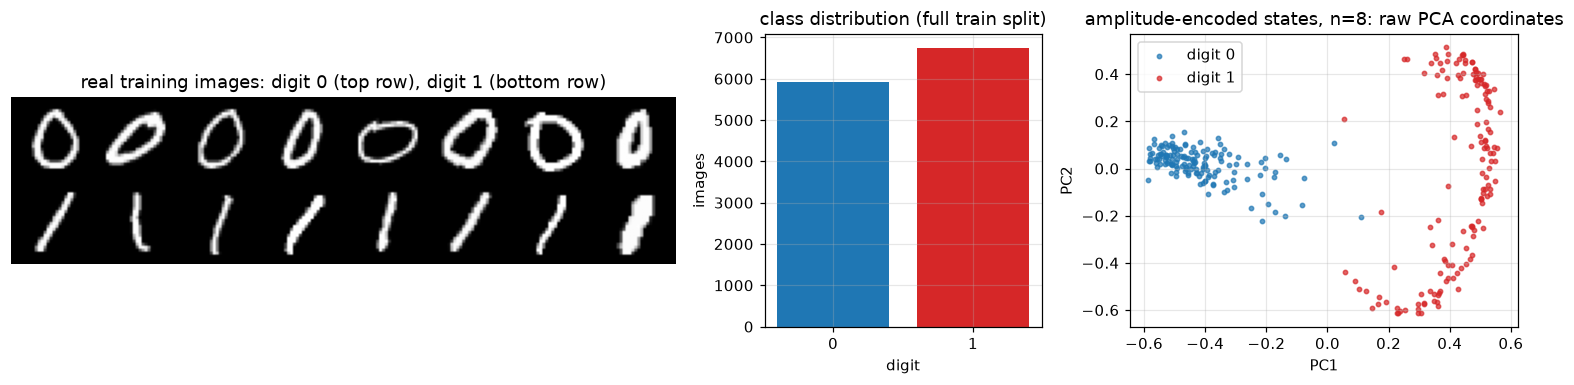

The amplitude-encoded MNIST states use amplitude encoding (no rotation angles), so there is no [0, pi]-scaled angle plot for this model.
PCA explained variance ratio: [0.387 0.153]


In [7]:
def load_mnist_pair(split):
    """Public Hugging Face mirror ylecun/mnist (parquet); fallback: OpenML copy through scikit-learn."""
    try:
        from huggingface_hub import hf_hub_download
        import pyarrow.parquet as pq
        path = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset",
                               local_dir=DATA_DIR, token=HF_TOKEN)
        df = pq.read_table(path).to_pandas()
        labs = df["label"].to_numpy()
        keep = np.isin(labs, MNIST_PAIR)
        imgs = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in df["image"][keep]])
        return imgs, labs[keep], "Hugging Face ylecun/mnist"
    except Exception as e:
        print("HF download failed (", type(e).__name__, "), falling back to OpenML")
        from sklearn.datasets import fetch_openml
        X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False, data_home=DATA_DIR)
        y = y.astype(int); sl = slice(0, 60000) if split == "train" else slice(60000, 70000)
        X, y = X[sl], y[sl]; keep = np.isin(y, MNIST_PAIR)
        return X[keep].reshape(-1, 28, 28).astype(np.uint8), y[keep], "OpenML mnist_784"

POOL = {}
for split in ("train", "test"):
    imgs, labs, src = load_mnist_pair(split)
    POOL[split] = (imgs, labs)
    print(f"{split}: images {imgs.shape}, dtype {imgs.dtype}, pixel range [{imgs.min()}, {imgs.max()}], "
          f"original labels/counts {dict(zip(*[x.tolist() for x in np.unique(labs, return_counts=True)]))}   source: {src}")
print("features: 784 pixel intensities p_r_c (row r, column c, 0..255) per image; before amplitude encoding each image is resized to 2^n pixels")
print("label meaning: digit value 0 -> class -1, digit value 1 -> class +1")

def sample_mnist(seed):
    """Fixed class-balanced subsets of the official train / test splits."""
    rng = np.random.default_rng(SEED + 17 * seed)
    out = {}
    for split, per in (("train", MNIST_TRAIN_PER_CLASS), ("test", MNIST_TEST_PER_CLASS)):
        imgs, labs = POOL[split]
        idx = np.concatenate([rng.choice(np.where(labs == c)[0], per, replace=False) for c in MNIST_PAIR])
        out[split] = (imgs[idx], np.where(labs[idx] == MNIST_PAIR[1], 1, -1))
    return out

def amp_encode(imgs, n):
    """Resize each 28x28 image to (2^ceil(n/2)) x (2^floor(n/2)) pixels and normalise: the amplitudes of an n-qubit state."""
    rows_, cols_ = 1 << ((n + 1) // 2), 1 << (n // 2)           # CHOICE: aspect ratio 1 or 2, bilinear/area resize, no fitted parameter
    X = np.stack([np.asarray(Image.fromarray(im).resize((cols_, rows_), Image.BILINEAR), dtype=float).ravel() for im in imgs])
    return X / np.linalg.norm(X, axis=1, keepdims=True)

MN0 = sample_mnist(0)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw={"width_ratios": [2.4, 1, 1.4]})
ax[0].axis("off"); ax[0].grid(False)
tile = np.vstack([np.hstack(list(MN0["train"][0][MN0["train"][1] == c][:8])) for c in (-1, 1)])
ax[0].imshow(tile, cmap="gray"); ax[0].set_title("real training images: digit 0 (top row), digit 1 (bottom row)")
cnt = [np.sum(POOL["train"][1] == c) for c in MNIST_PAIR]
ax[1].bar([str(c) for c in MNIST_PAIR], cnt, color=["tab:blue", "tab:red"]); ax[1].set_title("class distribution (full train split)")
ax[1].set_xlabel("digit"); ax[1].set_ylabel("images")
# PCA of the amplitude-encoded states (n = 8 qubits), fitted on the training split only
Xa = amp_encode(MN0["train"][0], 8); ya = MN0["train"][1]
pca = PCA(2, random_state=SEED).fit(Xa); Z = pca.transform(Xa)
for c, col, nm in ((-1, "tab:blue", "digit 0"), (1, "tab:red", "digit 1")):
    ax[2].scatter(Z[ya == c, 0], Z[ya == c, 1], s=8, c=col, label=nm, alpha=0.7)
ax[2].set_title("amplitude-encoded states, n=8: raw PCA coordinates"); ax[2].legend(); ax[2].set_xlabel("PC1"); ax[2].set_ylabel("PC2")
plt.tight_layout(); plt.show()
print("The amplitude-encoded MNIST states use amplitude encoding (no rotation angles), so there is no [0, pi]-scaled angle plot for this model.")
print("PCA explained variance ratio:", np.round(pca.explained_variance_ratio_, 3))

### 3.2 Haar-random states and their ground-truth labels

training Haar states: 300 states x 64 complex amplitudes -> real feature matrix (300, 128)
feature names: Re_a0..Re_a63, Im_a0..Im_a63  (a_k = amplitude of basis state |k>)
ground-truth label values / counts (teacher c = sign <Z_0 U_T>): {-1: 151, 1: 149}


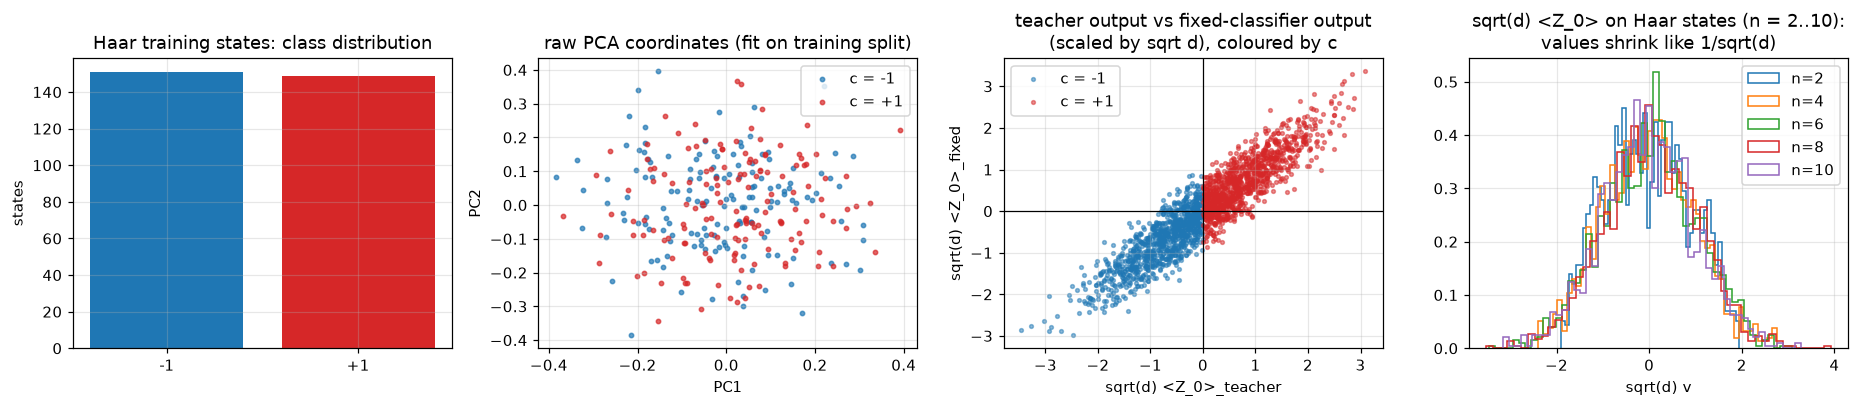

Angle encoding is not used for Haar states (they are the model input), so no [0, pi]-scaled coordinates apply.
A linear projection cannot separate the classes (the labels are a quadratic function of the amplitudes), which is why the classical linear model of section 8 stays near chance.


In [8]:
# One task at n = 6 qubits (d = 64): shape, features, labels, class distribution, projection coloured by the ground-truth label
n_demo = 6
tk = make_task(n_demo, 0)
Xh = np.hstack([tk["xr"], tk["xi"]])
print(f"training Haar states: {tk['xr'].shape[0]} states x {1 << n_demo} complex amplitudes -> real feature matrix {Xh.shape}")
print("feature names: Re_a0..Re_a%d, Im_a0..Im_a%d  (a_k = amplitude of basis state |k>)" % ((1 << n_demo) - 1, (1 << n_demo) - 1))
print("ground-truth label values / counts (teacher c = sign <Z_0 U_T>):", dict(zip(*[x.tolist() for x in np.unique(tk["y"], return_counts=True)])))
vc_d, vh_d, _ = haar_eval(tk, {"fixed": tk["th_fixed"]}, 2000)
sd = np.sqrt(1 << n_demo)

fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
ax[0].bar(["-1", "+1"], [np.sum(tk["y"] == -1), np.sum(tk["y"] == 1)], color=["tab:blue", "tab:red"])
ax[0].set_title("Haar training states: class distribution"); ax[0].set_ylabel("states")
pcah = PCA(2, random_state=SEED).fit(Xh); Zh = pcah.transform(Xh)
for c, col in ((-1, "tab:blue"), (1, "tab:red")):
    ax[1].scatter(Zh[tk["y"] == c, 0], Zh[tk["y"] == c, 1], s=8, c=col, alpha=0.7, label=f"c = {c:+d}")
ax[1].set_title("raw PCA coordinates (fit on training split)"); ax[1].legend(); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
lab_c = label_of(vc_d)
for c, col in ((-1, "tab:blue"), (1, "tab:red")):
    ax[2].scatter(sd * vc_d[lab_c == c], sd * vh_d["fixed"][lab_c == c], s=6, c=col, alpha=0.5, label=f"c = {c:+d}")
ax[2].axhline(0, c="k", lw=0.8); ax[2].axvline(0, c="k", lw=0.8)
ax[2].set_title("teacher output vs fixed-classifier output\n(scaled by sqrt d), coloured by c"); ax[2].set_xlabel("sqrt(d) <Z_0>_teacher"); ax[2].set_ylabel("sqrt(d) <Z_0>_fixed"); ax[2].legend()
# concentration of the outputs: the histogram of sqrt(d) v collapses onto one curve as n grows
for nn in (2, 4, 6, 8, 10):
    t_ = make_task(nn, 0); v_, _, _ = haar_eval(t_, {}, 1500)
    ax[3].hist(np.sqrt(1 << nn) * v_, bins=50, density=True, histtype="step", label=f"n={nn}")
ax[3].set_title("sqrt(d) <Z_0> on Haar states (n = 2..10):\nvalues shrink like 1/sqrt(d)"); ax[3].legend(); ax[3].set_xlabel("sqrt(d) v")
plt.tight_layout(); plt.show()
print("Angle encoding is not used for Haar states (they are the model input), so no [0, pi]-scaled coordinates apply.")
print("A linear projection cannot separate the classes (the labels are a quadratic function of the amplitudes), which is why the classical linear model of section 8 stays near chance.")

## Quantum Circuit Architecture

Two distinct architectures are executed: **A**, the Haar-input classifier (the Haar state is the input register, drawn as a state-preparation box;
RY layers, CX chain, final RY layer, `Z` measurement on qubit 0), and **B**, the MNIST classifier (the same ansatz after an amplitude-encoding
state-preparation circuit, drawn fully decomposed into `u`, `ry`, `rz`, `cx`). Both drawings are produced from the *same gate list* that the simulator
applies; the cell asserts that the drawn Qiskit circuit and the simulator give the same state and the same `<Z_0>`.

Assumptions where the paper is silent (it gives no circuit): gate set (RY, CX), CX direction (`q+1 -> q`), number of layers `L = N_LAYERS`, a final RY layer, measurement of `Z` on qubit 0,
and the use of a state-preparation black box for Haar inputs (the paper treats the input state as given).

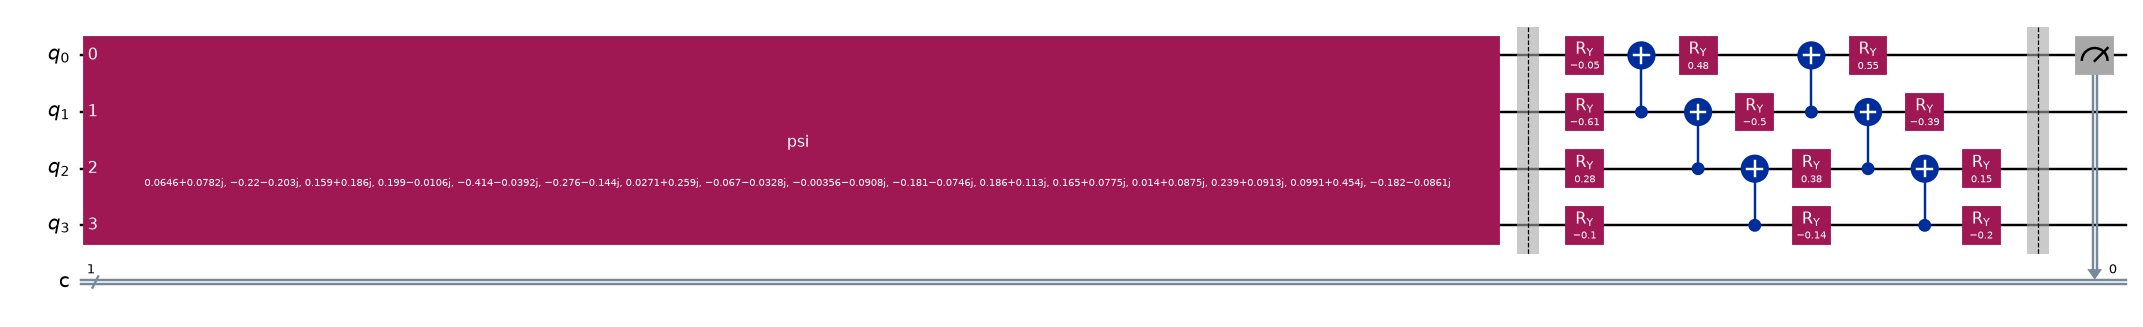

A: qubits = 4, depth (with state-preparation box) = 10, depth of the ansatz alone = 8, trainable parameters = 12 (n (L+1) with L = 2), measured qubit 0, classical bits = 1
   drawn circuit == simulator gate list, state and <Z_0>: asserted


In [9]:
def full_circuit(theta, n, L, psi, measure=True):
    qc = QuantumCircuit(n, 1 if measure else 0)
    qc.prepare_state(psi, list(range(n)), label="psi")
    qc.barrier()
    qc.compose(qiskit_ansatz(theta, n, L), inplace=True)
    if measure:
        qc.barrier(); qc.measure(0, 0)
    return qc

def gate_sequence_of(qc):
    seq = []
    for inst in qc.data:
        nm = inst.operation.name
        if nm in ("ry", "cx"):
            seq.append((nm, tuple(qc.find_bit(q).index for q in inst.qubits), inst.operation.params))
    return seq

# ---- architecture A: Haar input, n = 4 qubits (fixed-classifier angles of the demo task, rounded for display)
nA, LA = 4, N_LAYERS
tkA = make_task(nA, 0)
psiA = (lambda xr, xi: xr[0] + 1j * xi[0])(*haar_batch(np.random.default_rng(SEED), nA, 1))
qcA = full_circuit(np.round(tkA["th_fixed"], 2), nA, LA, psiA)
from IPython.display import display
display(qcA.draw("mpl", fold=40, scale=0.8))
# the drawn gates are exactly the simulator's gate list
exp_seq = [("ry", (a,), [round(float(tkA["th_fixed"][b]), 2)]) if k == "ry" else ("cx", (a, b), []) for k, a, b in gate_list(nA, LA)]
got_seq = gate_sequence_of(qcA)
assert [(a, b) for a, b, _ in exp_seq] == [(a, b) for a, b, _ in got_seq]
assert all(np.allclose(p1, p2) for (_, _, p1), (_, _, p2) in zip(exp_seq, got_seq))
# the drawn circuit gives the simulator's state and expectation value
thr = np.round(tkA["th_fixed"], 2)
sv = Statevector(full_circuit(thr, nA, LA, psiA, measure=False))
phi = apply_U(thr, nA, LA, psiA.real[None, :]) + 1j * apply_U(thr, nA, LA, psiA.imag[None, :])
assert np.allclose(sv.data, phi[0], atol=1e-10)
assert abs(sv.expectation_value(SparsePauliOp("I" * (nA - 1) + "Z")).real - expect_Z0(thr, nA, LA, psiA.real[None, :], psiA.imag[None, :])[0]) < 1e-10
print(f"A: qubits = {nA}, depth (with state-preparation box) = {qcA.depth()}, depth of the ansatz alone = {qiskit_ansatz(thr, nA, LA).depth()}, "
      f"trainable parameters = {n_params(nA, LA)} (n (L+1) with L = {LA}), measured qubit 0, classical bits = 1")
print("   drawn circuit == simulator gate list, state and <Z_0>: asserted")

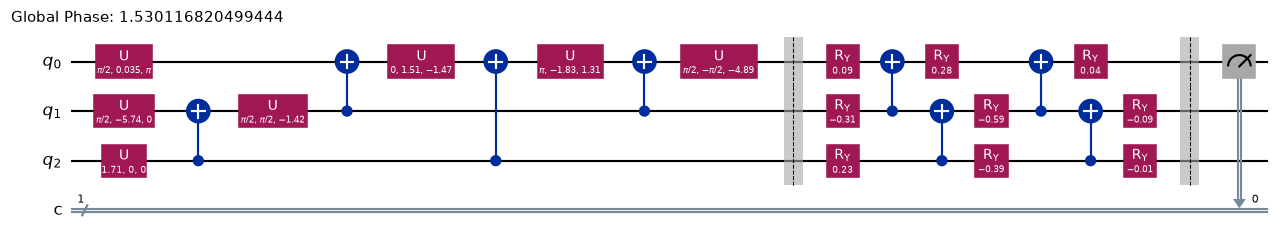

B: qubits = 3, depth (decomposed state preparation + ansatz + measurement) = 17, trainable parameters = 9 (the amplitude-encoding gates are fixed by the image, not trained)
   decomposed circuit == simulator state (up to global phase) and <Z_0>: asserted
Both architectures scale to n = 2..10 by changing n only; parameters n (L+1) =  [6, 9, 12, 15, 18, 21, 24, 27, 30]


In [10]:
# ---- architecture B: amplitude-encoded MNIST image, n = 3 qubits (4 x 2 pixels), state preparation fully decomposed
nB, LB = 3, N_LAYERS
imgB = MN0["train"][0][:1]
psiB = amp_encode(imgB, nB)[0]
thB = np.round(np.random.default_rng(SEED).normal(0, SIGMA_T, n_params(nB, LB)), 2)
qcB_full = full_circuit(thB, nB, LB, psiB.astype(complex), measure=True)
qcB = transpile(qcB_full, basis_gates=["ry", "rz", "cx", "u"], optimization_level=0)
display(qcB.draw("mpl", fold=45, scale=0.7))
svB = Statevector(transpile(full_circuit(thB, nB, LB, psiB.astype(complex), measure=False), basis_gates=["ry", "rz", "cx", "u"], optimization_level=0))
phiB = apply_U(thB, nB, LB, psiB[None, :])
assert abs(abs(np.vdot(svB.data, phiB[0])) - 1) < 1e-9                       # equal up to a global phase
assert abs(svB.expectation_value(SparsePauliOp("I" * (nB - 1) + "Z")).real - expect_Z0(thB, nB, LB, psiB[None, :], np.zeros((1, 1 << nB)))[0]) < 1e-9
print(f"B: qubits = {nB}, depth (decomposed state preparation + ansatz + measurement) = {qcB.depth()}, "
      f"trainable parameters = {n_params(nB, LB)} (the amplitude-encoding gates are fixed by the image, not trained)")
print("   decomposed circuit == simulator state (up to global phase) and <Z_0>: asserted")
print("Both architectures scale to n = 2..10 by changing n only; parameters n (L+1) = ", [n_params(n_, N_LAYERS) for n_ in NS])

## 5. Three attacks and one brute-force check, validated against each other

For a classifier with output `v(psi) = <psi|O|psi>` and label `sign v`, the adversary looks for the state `psi'` closest to `psi` with the opposite label.

* **Exact optimum** (closed form, section 1): rescale the two eigenspaces of `O` until `p+ = p- = 1/2`. We construct the explicit state, push it a hair across the boundary
  (`1e-6`) and assert that the label flips and that its fidelity with `psi` equals `F_flip`.
* **Exact-gradient attack** (DeepFool style): repeat `psi <- normalise(psi - (1+eta) v grad / |grad|^2)` with the exact tangent gradient `grad = 2 (O psi - v psi)` until the label flips, then bisect on the
  segment back to `psi`. It can only be farther than the exact optimum.
* **Margin attack** (one linearised step): the first DeepFool step `|v| / |grad|` converted to a fidelity.
* **Brute force** (`n = 2, 3`): SLSQP maximisation of `|<psi|phi>|` over all complex `phi` subject to `<phi|O|phi> = 0`, with random restarts. It must never beat the closed form and should reach it.

In [11]:
rng_a = np.random.default_rng(SEED + 5)
rows = []
for n in NS:
    L = N_LAYERS
    th = rng_a.normal(0, 1.0, n_params(n, L))                               # a random (untrained) projective classifier
    xr, xi = haar_batch(rng_a, n, N_ATTACK_CHECK)
    v = expect_Z0(th, n, L, xr, xi)
    F_exact = flip_fidelity(v)
    ar, ai = exact_attack_state(th, n, L, xr, xi)
    v2 = expect_Z0(th, n, L, ar, ai)
    flipped = np.all(label_of(v2) != label_of(v))
    F_act = fidelity_pair(xr, xi, ar, ai)
    ms, sr, si, ok = deepfool_attack(th, n, L, xr, xi)
    F_df = fidelity_pair(xr, xi, sr, si)
    F_margin = 1 / np.sqrt(1 + ms ** 2)
    assert flipped and np.abs(F_act - F_exact).max() < 1e-5, n
    assert ok.all() and (F_df - F_exact).min() > -1e-8, n                  # the gradient attack never beats the optimum
    rows.append(dict(n=n, d=1 << n, label_flipped=bool(flipped), max_abs_F_err=np.abs(F_act - F_exact).max(),
                     gradient_attack_success=float(ok.mean()), med_infid_exact=np.median(1 - F_exact),
                     ratio_gradient_over_exact=np.median((1 - F_df) / (1 - F_exact)), ratio_margin_over_exact=np.median((1 - F_margin) / (1 - F_exact))))
ATT = pd.DataFrame(rows)
print(ATT.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

# brute force with a generic optimiser on small systems
bf = []
for n in (2, 3):
    d = 1 << n; L = N_LAYERS
    th = rng_a.normal(0, 1.0, n_params(n, L))
    Um = apply_U(th, n, L, np.eye(d)).T
    O = Um.T @ np.diag(np.where(np.arange(d) % 2 == 0, 1., -1.)) @ Um
    xr, xi = haar_batch(rng_a, n, 5)
    for i in range(5):
        psi = xr[i] + 1j * xi[i]
        best = 0.0
        for r in range(8):
            z0 = np.concatenate([psi.real, psi.imag]) + 0.5 * rng_a.standard_normal(2 * d)
            f = lambda z: -abs(np.vdot(psi, z[:d] + 1j * z[d:])) ** 2 / (z @ z)
            c = lambda z: np.real(np.vdot(z[:d] + 1j * z[d:], O @ (z[:d] + 1j * z[d:]))) / (z @ z)
            res = minimize(f, z0, constraints=[{"type": "eq", "fun": c}], method="SLSQP", options={"maxiter": 400, "ftol": 1e-12})
            if abs(c(res.x)) < 1e-7:
                best = max(best, np.sqrt(-res.fun))
        Fx = float(flip_fidelity(expect_Z0(th, n, L, xr[i:i + 1], xi[i:i + 1]))[0])
        bf.append(dict(n=n, state=i, F_bruteforce=best, F_closed_form=Fx, gap=Fx - best))
BF = pd.DataFrame(bf)
print(BF.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
assert (BF["gap"] > -1e-7).all(), "brute force beat the closed form"
print("max gap closed form - brute force:", BF["gap"].max(), " (never negative: the closed form is the optimum)")

 n    d  label_flipped  max_abs_F_err  gradient_attack_success  med_infid_exact  ratio_gradient_over_exact  ratio_margin_over_exact
 2    4           True      4.764e-07                        1          0.01582                          1                    1.066
 3    8           True      4.106e-07                        1         0.005128                          1                    1.021
 4   16           True       2.41e-07                        1         0.002672                          1                    1.011
 5   32           True      2.377e-07                        1         0.002624                          1                    1.011
 6   64           True      1.973e-07                        1        0.0008737                          1                    1.004
 7  128           True       8.82e-08                        1        0.0005648                          1                    1.002
 8  256           True      8.862e-08                        1        0.0002

 n  state  F_bruteforce  F_closed_form       gap
 2      0      0.965614       0.965614 -0.000000
 2      1      0.944457       0.944457 -0.000000
 2      2      0.999987       0.999987  0.000000
 2      3      0.968767       0.968767 -0.000000
 2      4      0.999020       0.999020 -0.000000
 3      0      0.999951       0.999951  0.000000
 3      1      0.975822       0.975822 -0.000000
 3      2      0.963477       0.963477 -0.000000
 3      3      0.999680       0.999680  0.000000
 3      4      0.920139       0.920139 -0.000000
max gap closed form - brute force: 2.1094237467877974e-15  (never negative: the closed form is the optimum)


## 6. Experiment: nearest adversarial example for Haar-random inputs, `n = 2..10`

For every `(n, seed)` we draw a teacher, build the fixed classifier, train the student, and evaluate both on `N_TEST` fresh Haar states
(distances) and on another `N_TEST` fresh states (the misclassification probability `mu(M)`, so that `mu` and the distances are independent estimates).
Per state we record

* `H_h`: the distance to the nearest state with the **other label of `h`** (the adversarial example when `c` does not change);
* `H_M`: the distance to the nearest point of the misclassified set `M = {h != c}`, which is the object of Theorem 1: `0` if the state is already misclassified, otherwise
  `min(H_h, H_c)` (crossing the boundary of `h` or the boundary of `c`; both closed forms).

In [12]:
HAAR = {}
t_start = time.time()
for n in NS:
    for sd in range(N_SEEDS):
        t0 = time.time()
        tk = make_task(n, sd)
        th_tr, hist = fit_student(tk)
        thetas = {"fixed": tk["th_fixed"], "trained": th_tr}
        vc, vh, first = haar_eval(tk, thetas, 2 * N_TEST)
        # classical logistic regression on [Re psi, Im psi] (identical inputs), features scaled by sqrt(2d) for conditioning
        d = 1 << n; scl = np.sqrt(2 * d)
        lr = LogisticRegression(C=10.0, max_iter=500).fit(np.hstack([tk["xr"], tk["xi"]]) * scl, tk["y"])
        Xl = np.hstack(first)                                               # first chunk of the test states (unit vectors in R^{2d})
        w, b0 = lr.coef_[0] * scl, lr.intercept_[0]                         # decision function in the original coordinates
        lin_pred = label_of(Xl @ w + b0)
        lin_acc = float(np.mean(lin_pred == label_of(vc[:len(Xl)])))
        lin_F = linear_flip_fidelity(w, b0, Xl)
        acc = {k: float(np.mean(label_of(vh[k][:N_TEST]) == label_of(vc[:N_TEST]))) for k in thetas}
        tr_acc = float(np.mean(label_of(expect_Z0(th_tr, n, N_LAYERS, tk["xr"], tk["xi"])) == tk["y"]))
        HAAR[(n, sd)] = dict(vc=vc, vh=vh, lin_acc=lin_acc, lin_F=lin_F, acc=acc, tr_acc=tr_acc, loss=(hist[0], hist[-1]))
        print(f"n={n:2d} seed={sd}  train acc {tr_acc:.3f}  test acc fixed {acc['fixed']:.3f} trained {acc['trained']:.3f}  "
              f"linear model acc {lin_acc:.3f}   loss {hist[0]:.3f}->{hist[-1]:.3f}   ({time.time() - t0:.0f}s)", flush=True)
print(f"total {time.time() - t_start:.0f}s")

n= 2 seed=0  train acc 0.957  test acc fixed 0.849 trained 0.946  linear model acc 0.462   loss 0.594->0.284   (1s)


n= 2 seed=1  train acc 0.977  test acc fixed 0.890 trained 0.963  linear model acc 0.526   loss 0.307->0.222   (1s)


n= 3 seed=0  train acc 0.943  test acc fixed 0.867 trained 0.945  linear model acc 0.442   loss 0.624->0.294   (1s)


n= 3 seed=1  train acc 0.973  test acc fixed 0.853 trained 0.948  linear model acc 0.484   loss 0.665->0.268   (3s)


n= 4 seed=0  train acc 0.933  test acc fixed 0.904 trained 0.952  linear model acc 0.530   loss 0.321->0.252   (1s)


...

n= 9 seed=0  train acc 0.973  test acc fixed 0.895 trained 0.978  linear model acc 0.506   loss 0.555->0.319   (54s)


n= 9 seed=1  train acc 0.973  test acc fixed 0.895 trained 0.954  linear model acc 0.536   loss 0.423->0.248   (79s)


n=10 seed=0  train acc 0.947  test acc fixed 0.913 trained 0.957  linear model acc 0.490   loss 0.501->0.324   (628s)


n=10 seed=1  train acc 0.963  test acc fixed 0.878 trained 0.942  linear model acc 0.464   loss 0.765->0.292   (202s)


total 1042s


In [13]:
# ---- turn the raw outputs into distances (all closed forms) and the quantities of the theorem
DIST = {}       # (kind, n, seed) -> dict
for (n, sd), R in HAAR.items():
    d = 1 << n
    a, bsl = slice(0, N_TEST), slice(N_TEST, 2 * N_TEST)
    for kind in ("fixed", "trained"):
        vh, vc = R["vh"][kind], R["vc"]
        mis_b = label_of(vh[bsl]) != label_of(vc[bsl])
        mu = max(int(mis_b.sum()), 1) / N_TEST                              # mu(M) from the independent half (floor of one event)
        Fh, Fc = flip_fidelity(vh[a]), flip_fidelity(vc[a])
        mis = label_of(vh[a]) != label_of(vc[a])
        infid_h = 1 - Fh
        infid_M = np.where(mis, 0.0, 1 - np.maximum(Fh, Fc))
        DIST[(kind, n, sd)] = dict(d=d, mu=mu, mis_rate=float(mis.mean()), infid_h=infid_h, infid_M=infid_M,
                                   H_h=hs_dist(Fh), H_M=2 * np.sqrt(infid_M), absv=np.abs(vh[a]))

def pooled(kind, n, key):
    return np.concatenate([DIST[(kind, n, sd)][key] for sd in range(N_SEEDS)])

tab = []
for kind in ("fixed", "trained"):
    for n in NS:
        d = 1 << n
        tab.append(dict(classifier=kind, n=n, d=d,
                        accuracy=np.mean([HAAR[(n, sd)]["acc"][kind] for sd in range(N_SEEDS)]),
                        mu_M=np.mean([DIST[(kind, n, sd)]["mu"] for sd in range(N_SEEDS)]),
                        med_sqrt_d_absv=np.median(np.sqrt(d) * pooled(kind, n, "absv")),
                        med_H_h=np.median(pooled(kind, n, "H_h")), med_infid_h=np.median(pooled(kind, n, "infid_h")),
                        med_H_M=np.median(pooled(kind, n, "H_M")), med_infid_M=np.median(pooled(kind, n, "infid_M"))))
TAB = pd.DataFrame(tab)
print(TAB.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
print("sqrt(d)|v| should settle at the median of |N(0,1)| = 0.6745 (Haar concentration of the output).")

classifier  n    d  accuracy   mu_M  med_sqrt_d_absv  med_H_h  med_infid_h  med_H_M  med_infid_M
     fixed  2    4    0.8695   0.13           0.6931   0.2499      0.01561   0.1806     0.008153
     fixed  3    8      0.86  0.133           0.6903   0.1742     0.007589   0.1241     0.003851
     fixed  4   16    0.9205  0.074            0.675   0.1199     0.003592   0.1034     0.002674
     fixed  5   32    0.8875  0.107           0.6885  0.08626      0.00186  0.06721     0.001129
     fixed  6   64     0.859   0.14           0.7012  0.06205    0.0009626  0.04629    0.0005357
     fixed  7  128    0.8855  0.102           0.6801  0.04253    0.0004522  0.03348    0.0002802
     fixed  8  256     0.909  0.085           0.6886  0.03044    0.0002316  0.02538     0.000161
     fixed  9  512     0.895 0.1075           0.6516  0.02037    0.0001037  0.01605    6.441e-05
     fixed 10 1024    0.8955   0.11           0.6612  0.01461    5.338e-05  0.01116    3.114e-05
   trained  2    4    0.9545  

### 6.1 Scaling exponents

`log2 d = n`, so a power law `X ~ d^(-a)` is a straight line of slope `-a` in `log2 X` versus `n`. The paper predicts
`H^2 ~ d^(-1)` (Theorem 1, so slope `-1`) and an infidelity `1 - F ~ d^(-2)` (Eq. C4, slope `-2`). We fit on `n >= N_FIT_MIN`.

         slope log2 median H_h^2  slope log2 median H_M^2  slope log2 median (1-F)_h  slope log2 median (1-F)_M
fixed                     -1.021                   -1.011                     -1.021                     -1.011
trained                   -1.016                   -1.014                     -1.016                     -1.014
paper: H^2 ~ d^-1  -> slope -1 ;   1-F ~ d^-2 -> slope -2 ;   prediction from section 1: both -1


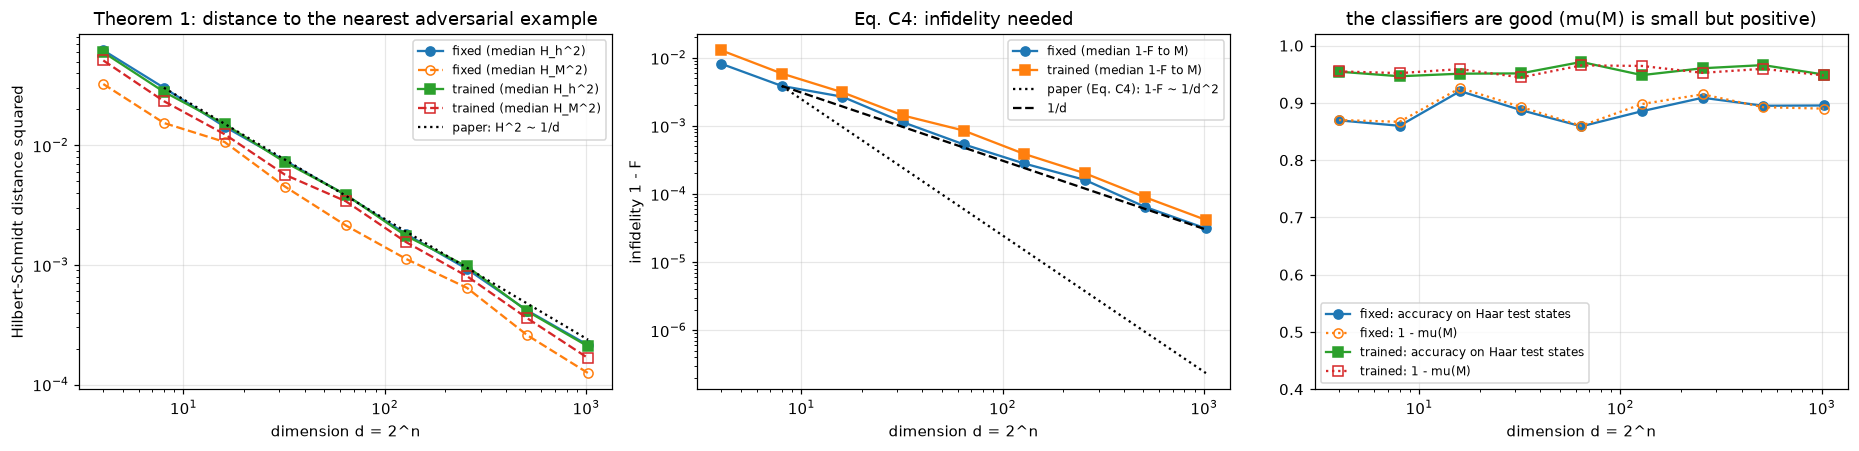

In [14]:
def slope(ns, y):
    return float(np.polyfit(ns, np.log2(y), 1)[0])
ns_fit = [n for n in NS if n >= N_FIT_MIN]
SL = {}
for kind in ("fixed", "trained"):
    sub = TAB[(TAB.classifier == kind) & (TAB.n.isin(ns_fit))]
    SL[kind] = dict(H2_h=slope(sub.n, sub.med_H_h ** 2), H2_M=slope(sub.n, sub.med_H_M ** 2),
                    infid_h=slope(sub.n, sub.med_infid_h), infid_M=slope(sub.n, sub.med_infid_M))
SLD = pd.DataFrame(SL).T
SLD.columns = ["slope log2 median H_h^2", "slope log2 median H_M^2", "slope log2 median (1-F)_h", "slope log2 median (1-F)_M"]
print(SLD.to_string(float_format=lambda x: f"{x:.3f}"))
print("paper: H^2 ~ d^-1  -> slope -1 ;   1-F ~ d^-2 -> slope -2 ;   prediction from section 1: both -1")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for kind, mk in (("fixed", "o"), ("trained", "s")):
    sub = TAB[TAB.classifier == kind]
    ax[0].loglog(sub.d, sub.med_H_h ** 2, mk + "-", label=f"{kind} (median H_h^2)")
    ax[0].loglog(sub.d, sub.med_H_M ** 2, mk + "--", mfc="none", label=f"{kind} (median H_M^2)")
d_ = np.array([2 ** n for n in ns_fit]); ref = TAB[(TAB.classifier == "fixed") & (TAB.n == ns_fit[0])].med_H_h.iloc[0] ** 2
ax[0].loglog(d_, ref * d_[0] / d_, "k:", label="paper: H^2 ~ 1/d")
ax[0].set_xlabel("dimension d = 2^n"); ax[0].set_ylabel("Hilbert-Schmidt distance squared"); ax[0].set_title("Theorem 1: distance to the nearest adversarial example"); ax[0].legend(fontsize=8)
for kind, mk in (("fixed", "o"), ("trained", "s")):
    sub = TAB[TAB.classifier == kind]
    ax[1].loglog(sub.d, sub.med_infid_M, mk + "-", label=f"{kind} (median 1-F to M)")
refI = TAB[(TAB.classifier == "fixed") & (TAB.n == ns_fit[0])].med_infid_M.iloc[0]
ax[1].loglog(d_, refI * (d_[0] / d_) ** 2, "k:", label="paper (Eq. C4): 1-F ~ 1/d^2")
ax[1].loglog(d_, refI * (d_[0] / d_), "k--", label="1/d")
ax[1].set_xlabel("dimension d = 2^n"); ax[1].set_ylabel("infidelity 1 - F"); ax[1].set_title("Eq. C4: infidelity needed"); ax[1].legend(fontsize=8)
for kind, mk in (("fixed", "o"), ("trained", "s")):
    sub = TAB[TAB.classifier == kind]
    ax[2].semilogx(sub.d, sub.accuracy, mk + "-", label=f"{kind}: accuracy on Haar test states")
    ax[2].semilogx(sub.d, 1 - sub.mu_M, mk + ":", mfc="none", label=f"{kind}: 1 - mu(M)")
ax[2].set_ylim(0.4, 1.02); ax[2].set_xlabel("dimension d = 2^n"); ax[2].set_title("the classifiers are good (mu(M) is small but positive)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Testing the bounds of Theorem 1 and Eq. C4 on every instance

For each `(classifier, n, seed)` and each `gamma = 1 - R`, with `mu = mu(M)` measured on the independent half:

* **Eq. 3 / B8 (paper):** `eps^2 = (4/d) ln(2 / (mu gamma))`; the theorem says the adversarial risk at this distance is at least `R = 1 - gamma`, i.e. the fraction of
  inputs with `H_M <= eps` must be `>= 1 - gamma`.
* **Rigorous Levy form (cited Theorem 3.7):** `eps = sqrt((4/d) ln(sqrt2/mu)) + sqrt((4/d) ln(sqrt2/gamma))` (the two-step argument of Appendix B adds `eps_1` and `eps_2`; the paper's Eq. B3 adds their squares).
* **Eq. C4 (paper):** `1 - F <= g/d^2`, `g = 2 ln(2/(mu gamma))`: the fraction of inputs with infidelity to `M` at most `g/d^2` must be `>= 1 - gamma`.

A *violation* means the observed fraction is below `1 - gamma` by more than three binomial standard errors.

   kind  n  cases  viol_eq3  viol_levy  viol_eqC4  min_frac_eq3  mean_frac_eqC4
  fixed  2      6         0          0          0         1.000           1.000
  fixed  3      6         0          0          0         1.000           1.000
  fixed  4      6         0          0          0         1.000           0.982
  fixed  5      6         0          0          0         1.000           0.901
  fixed  6      6         0          0          3         1.000           0.764
  fixed  7      6         0          0          4         1.000           0.630
  fixed  8      6         0          0          5         1.000           0.488
  fixed  9      6         0          0          6         1.000           0.403
  fixed 10      6         0          0          6         1.000           0.332
trained  2      6         0          0          0         1.000           1.000
trained  3      6         0          0          0         1.000           1.000
trained  4      6         0          0  

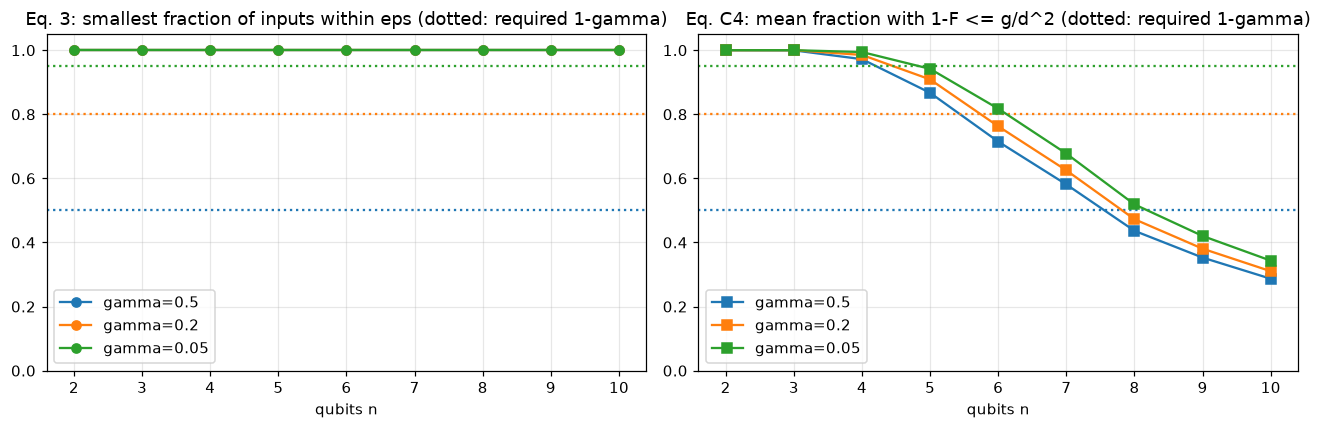

In [15]:
brows = []
for (kind, n, sd), D in DIST.items():
    d, mu = D["d"], D["mu"]
    for gam in GAMMAS:
        e_p = np.sqrt(4 / d * np.log(2 / (mu * gam)))
        e_r = np.sqrt(4 / d * np.log(np.sqrt(2) / mu)) + np.sqrt(4 / d * np.log(np.sqrt(2) / gam))
        g_ = 2 * np.log(2 / (mu * gam))
        tol = 3 * np.sqrt(gam * (1 - gam) / N_TEST)
        fp, fr, ff = float(np.mean(D["H_M"] <= e_p)), float(np.mean(D["H_M"] <= e_r)), float(np.mean(D["infid_M"] <= g_ / d ** 2))
        brows.append(dict(kind=kind, n=n, seed=sd, gamma=gam, mu=mu, eps_paper=e_p, frac_eq3=fp, viol_eq3=fp < 1 - gam - tol,
                          frac_levy=fr, viol_levy=fr < 1 - gam - tol, g_over_d2=g_ / d ** 2, frac_eqC4=ff, viol_eqC4=ff < 1 - gam - tol,
                          slack_eq3=e_p / max(np.quantile(D["H_M"], 1 - gam), 1e-12)))
BND = pd.DataFrame(brows)
summ = BND.groupby(["kind", "n"]).agg(cases=("viol_eq3", "size"), viol_eq3=("viol_eq3", "sum"), viol_levy=("viol_levy", "sum"),
                                       viol_eqC4=("viol_eqC4", "sum"), min_frac_eq3=("frac_eq3", "min"), mean_frac_eqC4=("frac_eqC4", "mean")).reset_index()
print(summ.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print()
print("Eq. 3 (B8) violations:", int(BND.viol_eq3.sum()), "of", len(BND), "| rigorous Levy form violations:", int(BND.viol_levy.sum()), "of", len(BND),
      "| Eq. C4 violations:", int(BND.viol_eqC4.sum()), "of", len(BND))
print("median slack of Eq. 3 (bound eps / (1-gamma) quantile of H_M):", round(float(BND.slack_eq3.median()), 2))
bad = BND[BND.viol_eqC4]
print("smallest n with an Eq. C4 violation:", int(bad.n.min()) if len(bad) else None)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for gam, col in zip(GAMMAS, ("tab:blue", "tab:orange", "tab:green")):
    m1 = BND[BND.gamma == gam].groupby("n").frac_eq3.min(); m2 = BND[BND.gamma == gam].groupby("n").frac_eqC4.mean()
    ax[0].plot(m1.index, m1.values, "o-", c=col, label=f"gamma={gam}"); ax[0].axhline(1 - gam, c=col, ls=":")
    ax[1].plot(m2.index, m2.values, "s-", c=col, label=f"gamma={gam}"); ax[1].axhline(1 - gam, c=col, ls=":")
ax[0].set_title("Eq. 3: smallest fraction of inputs within eps (dotted: required 1-gamma)"); ax[0].set_xlabel("qubits n"); ax[0].set_ylim(0, 1.05); ax[0].legend()
ax[1].set_title("Eq. C4: mean fraction with 1-F <= g/d^2 (dotted: required 1-gamma)"); ax[1].set_xlabel("qubits n"); ax[1].set_ylim(0, 1.05); ax[1].legend()
plt.tight_layout(); plt.show()

### 7.1 Where Eq. C3 breaks: the Hilbert-Schmidt to fidelity conversion

Eq. C3 claims `H(u_1, u_2)^2 >= 2d (1 - F(psi_1, psi_2))` for `psi_i = u_i|b>`. The step "`max_i <b_i|...|b_i> <= <b|...|b>`" in Eq. C2 goes the wrong way (the maximum is *at least* the value at `b`).
We test the inequality directly with explicit unitaries: take a Haar unitary `u_1`, a nearby state `psi_2`, and the **minimal rotation** `R` (in the plane of `b` and `u_1^dagger psi_2`) so that `u_2 = u_1 R` satisfies `u_2 |b> = psi_2`.
Then `H^2 = 2d - 2 Re Tr(R) = 4 (1 - F)` exactly, which is *smaller* than `2d(1-F)` as soon as `d > 2`. This is also what makes the numerical infidelity scale like `1/d` rather than `1/d^2`.

In [16]:
rng_c = np.random.default_rng(SEED + 9)
crow = []
for n in (1, 2, 3, 4, 5):
    d = 1 << n
    for rep in range(3):
        G = rng_c.standard_normal((d, d)) + 1j * rng_c.standard_normal((d, d))
        Q, Rr = np.linalg.qr(G); u1 = Q * (np.diag(Rr) / np.abs(np.diag(Rr)))           # Haar unitary
        u1 = u1 / np.linalg.det(u1) ** (1 / d)                                           # SU(d)
        b = np.zeros(d, complex); b[0] = 1
        psi1 = u1 @ b
        psi2 = psi1 + 0.3 * (rng_c.standard_normal(d) + 1j * rng_c.standard_normal(d)) / np.sqrt(2 * d); psi2 /= np.linalg.norm(psi2)
        bp = u1.conj().T @ psi2; bp = bp * np.exp(-1j * np.angle(bp[0]))                  # phase-align so <b|b'> > 0
        cth = bp[0].real; w = bp.copy(); w[0] = 0; w = w / np.linalg.norm(w); sth = np.sqrt(1 - cth ** 2)
        P = np.outer(b, b.conj()) + np.outer(w, w.conj())
        Rm = np.eye(d) + (cth - 1) * P + sth * (np.outer(w, b.conj()) - np.outer(b, w.conj()))
        u2 = u1 @ Rm
        assert np.allclose(u2.conj().T @ u2, np.eye(d)) and np.isclose(np.linalg.det(u2), 1)
        Fid = abs(np.vdot(psi1, u2 @ b))
        assert np.allclose(u2 @ b, u1 @ bp), "u2 maps b to the phase-aligned psi2"
        H2 = np.real(np.trace((u1 - u2).conj().T @ (u1 - u2)))
        crow.append(dict(n=n, d=d, H2=H2, four_1mF=4 * (1 - Fid), paper_bound_2d_1mF=2 * d * (1 - Fid), inequality_C3_holds=bool(H2 >= 2 * d * (1 - Fid) - 1e-12)))
C3 = pd.DataFrame(crow)
print(C3.groupby("n").agg(d=("d", "first"), H2=("H2", "mean"), four_1mF=("four_1mF", "mean"), paper_bound=("paper_bound_2d_1mF", "mean"),
                          holds=("inequality_C3_holds", "mean")).to_string(float_format=lambda x: f"{x:.5f}"))
print("H^2 equals 4(1-F) in every case:", bool(np.allclose(C3.H2, C3.four_1mF)))
C3_counter = int((~C3.inequality_C3_holds).sum())
print(f"Eq. C3 violated in {C3_counter} of {len(C3)} explicit constructions (all with d > 2)")

    d      H2  four_1mF  paper_bound   holds
n                                           
1   2 0.08799   0.08799      0.08799 1.00000
2   4 0.26577   0.26577      0.53153 0.00000
3   8 0.11870   0.11870      0.47480 0.00000
4  16 0.14833   0.14833      1.18666 0.00000
5  32 0.16343   0.16343      2.61493 0.00000
H^2 equals 4(1-F) in every case: True
Eq. C3 violated in 12 of 15 explicit constructions (all with d > 2)


### 7.2 Theorem 2a: what the measured fidelity scaling implies for the certification cost

Eq. C5 needs `N >= 1/(Delta eta^2)` with the precision `eta` smaller than the infidelity that separates `sigma` from the nearest adversarial state.
Using the measured median infidelity to the misclassified set as `eta` (and `Delta = 0.1`), the implied cost grows like `d^p`; the paper has `p = 4`.

In [17]:
DELTA = 0.1
nrows = []
for kind in ("fixed", "trained"):
    sub = TAB[(TAB.classifier == kind) & (TAB.n.isin(ns_fit))]
    Nreq = 1 / (DELTA * sub.med_infid_M.values ** 2)
    p_meas = float(np.polyfit(sub.n, np.log2(Nreq), 1)[0])
    nrows.append(dict(classifier=kind, N_at_n3=Nreq[0], N_at_nmax=Nreq[-1], measured_exponent_p=p_meas, paper_exponent_p=4.0))
T2 = pd.DataFrame(nrows)
print(T2.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
print("The cost is still exponential in the number of qubits (d^p with p about 2), but the exponent is not 4.")

classifier   N_at_n3  N_at_nmax  measured_exponent_p  paper_exponent_p
     fixed 6.742e+05  1.031e+10                2.021                 4
   trained  2.91e+05  5.785e+09                2.028                 4
The cost is still exponential in the number of qubits (d^p with p about 2), but the exponent is not 4.


### 7.3 Appendix A: small input perturbations do not change continuous outputs much

Appendix A shows `|v(sigma) - v(rho)| <= 2 Tr(O) sqrt(chi (2 - chi))` for `O >= 0` and `F(sigma, rho) >= 1 - chi`. We test it on the pairs `(psi, psi')` produced by the exact attack (the *worst* case: the output moves by exactly
the margin) and on random perturbations, with `O` the projector onto the `+1` eigenspace of the classifier (`Tr O = d/2`), and also test the sharper operator-norm form `|Delta v| <= ||O|| * 2 sqrt(1 - F^2)`.

In [18]:
rng_p = np.random.default_rng(SEED + 11)
arows = []
for n in NS:
    L = N_LAYERS; d = 1 << n
    th = rng_p.normal(0, 1.0, n_params(n, L))
    xr, xi = haar_batch(rng_p, n, 200)
    pp = lambda ar_, ai_: 0.5 * (expect_Z0(th, n, L, ar_, ai_) + 1)                    # <psi|Pi_+|psi>, Pi_+ = projector (a positive observable)
    ar, ai = exact_attack_state(th, n, L, xr, xi)
    nr_ = xr + 0.05 * rng_p.standard_normal(xr.shape) / np.sqrt(d); ni_ = xi + 0.05 * rng_p.standard_normal(xi.shape) / np.sqrt(d)
    nn_ = np.sqrt((nr_ ** 2 + ni_ ** 2).sum(1, keepdims=True)); nr_, ni_ = nr_ / nn_, ni_ / nn_
    for nm, (br, bi) in (("exact attack", (ar, ai)), ("random", (nr_, ni_))):
        Fq = np.clip(fidelity_pair(xr, xi, br, bi), 0, 1); chi = 1 - Fq
        dv = np.abs(pp(xr, xi) - pp(br, bi))
        b_paper = 2 * (d / 2) * np.sqrt(chi * (2 - chi)); b_op = 2 * np.sqrt(np.clip(1 - Fq ** 2, 0, None))
        arows.append(dict(n=n, pair=nm, max_dv=dv.max(), holds_paper=bool(np.all(dv <= b_paper + 1e-9)), holds_opnorm=bool(np.all(dv <= b_op + 1e-9)),
                          median_dv_over_opnorm_bound=float(np.median(dv / np.maximum(b_op, 1e-15)))))
APA = pd.DataFrame(arows)
print(APA.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
AppA_ok = bool(APA.holds_paper.all() and APA.holds_opnorm.all())
print("Appendix A bound holds on all pairs:", AppA_ok, "(for the projective measurement Tr O = d/2, so the paper's form is loose by a factor of order d)")

 n         pair   max_dv  holds_paper  holds_opnorm  median_dv_over_opnorm_bound
 2 exact attack   0.4745         True          True                        0.492
 2       random   0.1141         True          True                       0.1292
 3 exact attack   0.4697         True          True                       0.4956
 3       random  0.05034         True          True                      0.09271
 4 exact attack   0.3146         True          True                       0.4984
 4       random  0.04126         True          True                      0.05612
 5 exact attack   0.2474         True          True                       0.4993
 5       random    0.025         True          True                       0.0425
 6 exact attack   0.1949         True          True                       0.4995
 6       random  0.01612         True          True                      0.02839
 7 exact attack   0.1198         True          True                       0.4998
 7       random  0.01119    

## 8. A classical model on identical inputs

The paper claims the effect is independent of the classification protocol. A classical linear classifier acting on the same Haar inputs, written as the real vector `[Re psi, Im psi]` on the unit sphere of `R^(2d)`,
has an exact nearest-flip distance on the sphere: with `w`, `b` its weights, the boundary `w.x' + b = 0` meets the sphere in a circle at polar angle `arccos(-b/|w|)` from `w`, and the distance from `x`
is the difference of polar angles. We report the *infidelity-equivalent* `1 - cos(angle)` so that it is on the same scale as the quantum numbers. The classical model is trained on exactly the same labelled Haar states.
(It cannot learn the quadratic teacher, so its accuracy stays near chance; its adversarial distance still shows the dimension dependence.)

In [19]:
crow = []
for n in NS:
    d = 1 << n
    infid = np.concatenate([1 - HAAR[(n, sd)]["lin_F"] for sd in range(N_SEEDS)])
    crow.append(dict(n=n, d=d, linear_accuracy=np.mean([HAAR[(n, sd)]["lin_acc"] for sd in range(N_SEEDS)]),
                     med_infid_linear=np.nanmedian(infid),
                     med_infid_quantum_h=TAB[(TAB.classifier == "trained") & (TAB.n == n)].med_infid_h.iloc[0]))
CL = pd.DataFrame(crow)
print(CL.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
sub = CL[CL.n.isin(ns_fit)]
slope_lin = float(np.polyfit(sub.n, np.log2(sub.med_infid_linear), 1)[0]); slope_q = float(np.polyfit(sub.n, np.log2(sub.med_infid_quantum_h), 1)[0])
print(f"slope of log2 median infidelity: linear classical model {slope_lin:.3f}, quantum trained VQC {slope_q:.3f}; both close to -1 (a dimension effect, not a quantum effect)")

 n    d  linear_accuracy  med_infid_linear  med_infid_quantum_h
 2    4            0.494           0.04323              0.01502
 3    8            0.463           0.01795             0.007018
 4   16              0.5          0.006623             0.003772
 5   32            0.508          0.003145             0.001806
 6   64            0.491           0.00192            0.0009698
 7  128            0.503         0.0008329            0.0004365
 8  256            0.507         0.0004373            0.0002433
 9  512            0.521         0.0002644            0.0001022
10 1024            0.477         0.0001013            5.208e-05
slope of log2 median infidelity: linear classical model -1.015, quantum trained VQC -1.016; both close to -1 (a dimension effect, not a quantum effect)


## 9. Contrast: real data on a low-dimensional manifold (MNIST digits 0 and 1, amplitude encoded)

The theorem concerns *Haar-random* inputs. Real data lie on a thin manifold, and a classifier trained on them can place the boundary far from the data, so the distance to the nearest adversarial example
need not shrink with `n`. We train the same VQC family (angles initialised at random, logistic loss on `beta <Z_0>`, `beta = 4`) on amplitude-encoded MNIST states `n = 2..10`, using the same exact attack
(perturbations are unrestricted states, as in the paper's threat model), and compare with a classical logistic regression, a random forest and an RBF-SVM on the identical amplitude vectors.
Distances are reported for correctly classified test images only.

In [20]:
MN = {}
t0 = time.time()
for n in NS:
    for sd in range(N_SEEDS):
        S_ = sample_mnist(sd)
        d = 1 << n
        Xtr, ytr = amp_encode(S_["train"][0], n), S_["train"][1]
        Xte, yte = amp_encode(S_["test"][0], n), S_["test"][1]
        rng = np.random.default_rng(SEED + 23 * n + sd)
        th0 = rng.normal(0, SIGMA_T, n_params(n, N_LAYERS))
        th, hist = train_vqc(Xtr, np.zeros_like(Xtr), ytr.astype(float), n, N_LAYERS, th0, MNIST_STEPS, LR, MNIST_BETA, batch=BATCH, seed=SEED + n)
        v = expect_Z0(th, n, N_LAYERS, Xte, np.zeros_like(Xte))
        ok = label_of(v) == yte
        infid_q = (1 - flip_fidelity(v))[ok]
        scl = np.sqrt(d)
        lr = LogisticRegression(C=10.0, max_iter=500).fit(Xtr * scl, ytr)
        w, b0 = lr.coef_[0] * scl, lr.intercept_[0]
        ok_l = label_of(Xte @ w + b0) == yte
        infid_l = (1 - linear_flip_fidelity(w, b0, Xte))[ok_l]
        rf = RandomForestClassifier(100, random_state=SEED, n_jobs=1).fit(Xtr, ytr)
        sv_ = SVC(kernel="rbf", C=10.0, gamma="scale").fit(Xtr, ytr)
        MN[(n, sd)] = dict(acc_q=float(ok.mean()), acc_lin=float(ok_l.mean()), acc_rf=float(rf.score(Xte, yte)), acc_svc=float(sv_.score(Xte, yte)),
                           infid_q=infid_q, infid_lin=infid_l, absv=np.abs(v[ok]))
        print(f"n={n:2d} seed={sd}  acc VQC {ok.mean():.3f}  logistic {ok_l.mean():.3f}  RF {MN[(n, sd)]['acc_rf']:.3f}  RBF-SVC {MN[(n, sd)]['acc_svc']:.3f}   "
              f"median infidelity to flip: VQC {np.median(infid_q) if len(infid_q) else float('nan'):.3e}, logistic {np.median(infid_l) if len(infid_l) else float('nan'):.3e}  ({time.time() - t0:.0f}s)", flush=True)
mrows = []
for n in NS:
    iq = np.concatenate([MN[(n, sd)]["infid_q"] for sd in range(N_SEEDS)]); il = np.concatenate([MN[(n, sd)]["infid_lin"] for sd in range(N_SEEDS)])
    mrows.append(dict(n=n, d=1 << n, acc_VQC=np.mean([MN[(n, sd)]["acc_q"] for sd in range(N_SEEDS)]), acc_logistic=np.mean([MN[(n, sd)]["acc_lin"] for sd in range(N_SEEDS)]),
                      acc_RF=np.mean([MN[(n, sd)]["acc_rf"] for sd in range(N_SEEDS)]), acc_RBF_SVC=np.mean([MN[(n, sd)]["acc_svc"] for sd in range(N_SEEDS)]),
                      med_infid_VQC=np.median(iq), med_infid_logistic=np.nanmedian(il)))
MNT = pd.DataFrame(mrows)
print(MNT.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

n= 2 seed=0  acc VQC 0.634  logistic 0.650  RF 0.622  RBF-SVC 0.680   median infidelity to flip: VQC 7.881e-04, logistic 7.028e-04  (2s)


n= 2 seed=1  acc VQC 0.448  logistic 0.654  RF 0.608  RBF-SVC 0.648   median infidelity to flip: VQC 9.669e-04, logistic 7.754e-04  (4s)


n= 3 seed=0  acc VQC 0.596  logistic 0.712  RF 0.778  RBF-SVC 0.792   median infidelity to flip: VQC 8.097e-04, logistic 5.451e-04  (6s)


n= 3 seed=1  acc VQC 0.622  logistic 0.662  RF 0.708  RBF-SVC 0.780   median infidelity to flip: VQC 8.809e-04, logistic 3.292e-04  (8s)


n= 4 seed=0  acc VQC 0.950  logistic 0.994  RF 0.992  RBF-SVC 0.994   median infidelity to flip: VQC 1.195e-02, logistic 7.924e-03  (11s)


...

n= 9 seed=0  acc VQC 0.934  logistic 0.996  RF 0.998  RBF-SVC 0.996   median infidelity to flip: VQC 2.532e-02, logistic 6.457e-02  (57s)


n= 9 seed=1  acc VQC 0.940  logistic 1.000  RF 0.998  RBF-SVC 1.000   median infidelity to flip: VQC 2.536e-02, logistic 7.886e-02  (70s)


n=10 seed=0  acc VQC 0.878  logistic 0.996  RF 0.996  RBF-SVC 0.996   median infidelity to flip: VQC 4.920e-03, logistic 7.703e-02  (110s)


n=10 seed=1  acc VQC 0.844  logistic 1.000  RF 0.998  RBF-SVC 1.000   median infidelity to flip: VQC 5.698e-03, logistic 8.724e-02  (153s)


 n    d  acc_VQC  acc_logistic  acc_RF  acc_RBF_SVC  med_infid_VQC  med_infid_logistic
 2    4    0.541         0.652   0.615        0.664      0.0008281           0.0007648
 3    8    0.609         0.687   0.743        0.786      0.0008617           0.0004074
 4   16    0.957         0.991   0.993        0.992        0.01393            0.007171
 5   32    0.947         0.989   0.997         0.99        0.01635            0.007411
 6   64    0.951         0.998   0.998        0.998        0.04422             0.06137
 7  128    0.932         0.998   0.998        0.998        0.03018             0.05835
 8  256    0.939         0.998   0.998        0.998        0.02837             0.06471
 9  512    0.937         0.998   0.998        0.998        0.02532             0.07035
10 1024    0.861         0.998   0.997        0.998       0.005159             0.08338


MNIST qubit numbers used for the fit (accuracy >= 0.9): [4, 5, 6, 7, 8, 9]
slope of log2 median infidelity versus n (n in [4, 5, 6, 7, 8, 9]):  MNIST VQC 0.176 | MNIST logistic 0.736 | Haar trained VQC -1.016 | Haar prediction -1


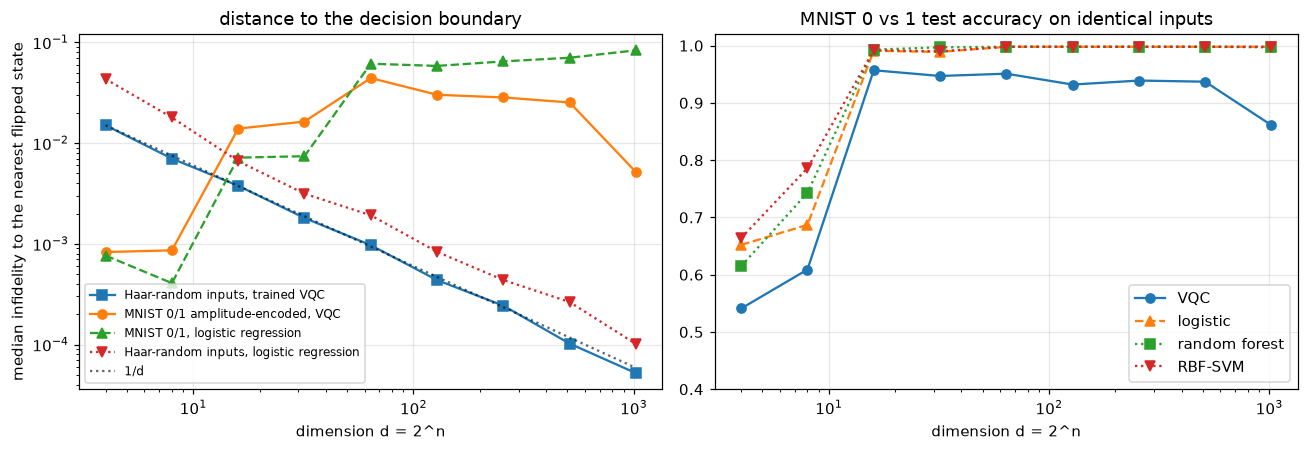

In [21]:
# fit only where the MNIST classifier actually works (mean VQC accuracy >= 0.9): at n = 2, 3 the image is resized to 2x2 / 4x2 pixels and the digits are not separable
ns_mn = [int(r.n) for r in MNT.itertuples() if r.acc_VQC >= 0.9 and r.n >= N_FIT_MIN]
subm = MNT[MNT.n.isin(ns_mn)]
if len(ns_mn) >= 3:
    slope_mn_q = float(np.polyfit(subm.n, np.log2(subm.med_infid_VQC), 1)[0]); slope_mn_l = float(np.polyfit(subm.n, np.log2(subm.med_infid_logistic), 1)[0])
else:
    slope_mn_q = slope_mn_l = float("nan")
print("MNIST qubit numbers used for the fit (accuracy >= 0.9):", ns_mn)
slope_haar_tr = SL["trained"]["infid_h"]
print(f"slope of log2 median infidelity versus n (n in {ns_mn}):  MNIST VQC {slope_mn_q:.3f} | MNIST logistic {slope_mn_l:.3f} | Haar trained VQC {slope_haar_tr:.3f} | Haar prediction -1")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sh = TAB[TAB.classifier == "trained"]
ax[0].loglog(sh.d, sh.med_infid_h, "s-", label="Haar-random inputs, trained VQC")
ax[0].loglog(MNT.d, MNT.med_infid_VQC, "o-", label="MNIST 0/1 amplitude-encoded, VQC")
ax[0].loglog(MNT.d, MNT.med_infid_logistic, "^--", label="MNIST 0/1, logistic regression")
ax[0].loglog(CL.d, CL.med_infid_linear, "v:", label="Haar-random inputs, logistic regression")
dd = sh.d.values.astype(float); ax[0].loglog(dd, sh.med_infid_h.iloc[0] * dd[0] / dd, "k:", alpha=0.6, label="1/d")
ax[0].set_xlabel("dimension d = 2^n"); ax[0].set_ylabel("median infidelity to the nearest flipped state"); ax[0].set_title("distance to the decision boundary"); ax[0].legend(fontsize=8)
ax[1].semilogx(MNT.d, MNT.acc_VQC, "o-", label="VQC"); ax[1].semilogx(MNT.d, MNT.acc_logistic, "^--", label="logistic")
ax[1].semilogx(MNT.d, MNT.acc_RF, "s:", label="random forest"); ax[1].semilogx(MNT.d, MNT.acc_RBF_SVC, "v:", label="RBF-SVM")
ax[1].set_ylim(0.4, 1.02); ax[1].set_xlabel("dimension d = 2^n"); ax[1].set_title("MNIST 0 vs 1 test accuracy on identical inputs"); ax[1].legend()
plt.tight_layout(); plt.show()

## 10. Paper versus this notebook: one verdict per claim

The paper reports no measured numbers, so "paper" means the analytic prediction. Verdict rules (stated before looking at the data):
exponent *reproduced* if the fitted slope is within `0.15` of the predicted one; bound *holds* if no violation is found (3 binomial standard errors); a claim is *not reproduced* if the measured exponent or inequality contradicts it;
*cannot be checked* if nothing numerical can be tested.

In [22]:
def verdict_slope(meas, pred, tol=0.15):
    return "reproduced" if abs(meas - pred) <= tol else f"not reproduced (measured {meas:.2f}, predicted {pred:.2f})"
rowsV = []
sl_f, sl_t = SL["fixed"]["H2_M"], SL["trained"]["H2_M"]
rowsV.append(dict(claim="Thm 1 scaling: H^2 ~ d^-1 (distance to nearest adversarial state ~ d^-1/2), Haar inputs",
                  paper="slope of log2 H^2 vs n = -1", notebook=f"fixed {sl_f:.2f}, trained {sl_t:.2f} (H_M); H_h: {SL['fixed']['H2_h']:.2f}, {SL['trained']['H2_h']:.2f}",
                  verdict=verdict_slope(np.mean([sl_f, sl_t]), -1.0)))
rowsV.append(dict(claim="Thm 1 / Eq. 3 (B8): adversarial risk >= R once H^2 >= (4/d) ln(2/(mu(1-R)))",
                  paper="holds for every d, mu, R", notebook=f"{int(BND.viol_eq3.sum())} violations in {len(BND)} (classifier, n, seed, gamma) cases; median slack {BND.slack_eq3.median():.1f}x",
                  verdict="bound holds (never violated)" if BND.viol_eq3.sum() == 0 else "bound violated"))
rowsV.append(dict(claim="Rigorous two-step Levy form (eps_1 + eps_2, cited Theorem 3.7)",
                  paper="implied by (sqrt 2, 1/4)-normal Levy family", notebook=f"{int(BND.viol_levy.sum())} violations in {len(BND)} cases",
                  verdict="bound holds (never violated)" if BND.viol_levy.sum() == 0 else "bound violated"))
sl_if, sl_it = SL["fixed"]["infid_M"], SL["trained"]["infid_M"]
first_bad = int(BND[BND.viol_eqC4].n.min()) if BND.viol_eqC4.any() else None
rowsV.append(dict(claim="Eq. C4: infidelity 1-F <= g/d^2 suffices (scaling d^-2)",
                  paper="slope of log2 (1-F) vs n = -2; fraction within g/d^2 >= R",
                  notebook=f"measured slope fixed {sl_if:.2f}, trained {sl_it:.2f}; {int(BND.viol_eqC4.sum())} violations in {len(BND)} cases, first at n={first_bad}",
                  verdict=("not reproduced (infidelity scales as d^-1; the bound is violated for larger n)" if BND.viol_eqC4.any() or abs(np.mean([sl_if, sl_it]) + 2) > 0.15
                           else "reproduced")))
rowsV.append(dict(claim="Eq. C3: H(u1,u2)^2 >= 2d(1-F)",
                  paper="holds for all unitaries with psi_i = u_i b", notebook=f"violated in {C3_counter} of {len(C3)} explicit constructions; H^2 = 4(1-F) exactly",
                  verdict="not reproduced (false as stated for d > 2)" if C3_counter > 0 else "reproduced"))
p_meas = float(T2.measured_exponent_p.mean())
rowsV.append(dict(claim="Thm 2a/2b: N >= d^4/(g^2 Delta) certification copies (exponential in n)",
                  paper="exponent 4 in d", notebook=f"implied exponent {p_meas:.2f} in d (fixed {T2.measured_exponent_p.iloc[0]:.2f}, trained {T2.measured_exponent_p.iloc[1]:.2f}); still exponential in the qubit number",
                  verdict=("reproduced" if abs(p_meas - 4.0) <= 0.3 else f"not reproduced (implied exponent {p_meas:.2f} vs 4); qualitative exponential-in-qubits cost reproduced")))
rowsV.append(dict(claim="Appendix A: |v(sigma)-v(rho)| <= 2 Tr(O) sqrt(chi(2-chi)) for O >= 0",
                  paper="holds", notebook=f"holds on all {len(APA)} (n, pair type) batches; also the operator-norm form", verdict="bound holds (never violated)" if AppA_ok else "bound violated"))
rowsV.append(dict(claim="Independence of the protocol: classical linear model on identical inputs shows the same dimension effect",
                  paper="qualitative", notebook=f"classical slope of log2 median infidelity {slope_lin:.2f} vs quantum {slope_q:.2f}", verdict=verdict_slope(slope_lin, slope_q, 0.3)))
rowsV.append(dict(claim="Low-dimensional real data (MNIST 0/1, amplitude encoding): decay slower than for Haar states (not a paper claim)",
                  paper="not stated (theorem is for Haar-random inputs)", notebook=f"MNIST VQC slope {slope_mn_q:.2f} (n in {ns_mn}) vs Haar {slope_haar_tr:.2f}",
                  verdict="cannot be checked (not a claim of the paper); observation: " + ("too few working MNIST sizes to fit" if np.isnan(slope_mn_q) else ("slower decay" if slope_mn_q > slope_haar_tr + 0.15 else "no slower decay"))))
rowsV.append(dict(claim="Thm 2a/2b protocol claims (copies and calls of fidelity-estimation protocols)",
                  paper="d^4 lower bound for the protocol of Flammia and Liu", notebook="the certification protocols are not simulated; only the arithmetic consequence above",
                  verdict="cannot be checked"))
VERD = pd.DataFrame(rowsV)
pd.set_option("display.max_colwidth", 120)
print(VERD.to_string(index=False))
n_rep = VERD.verdict.str.startswith(("reproduced", "bound holds")).sum(); n_not = VERD.verdict.str.startswith(("not reproduced", "bound violated")).sum()
n_cc = VERD.verdict.str.startswith("cannot").sum()
print(f"\nverdict counts: reproduced/holds = {n_rep}, not reproduced/violated = {n_not}, cannot be checked = {n_cc}  (of {len(VERD)})")

                                                                                                           claim                                                     paper                                                                                     notebook                                                                                        verdict
                         Thm 1 scaling: H^2 ~ d^-1 (distance to nearest adversarial state ~ d^-1/2), Haar inputs                               slope of log2 H^2 vs n = -1                                          fixed -1.01, trained -1.01 (H_M); H_h: -1.02, -1.02                                                                                     reproduced
                                     Thm 1 / Eq. 3 (B8): adversarial risk >= R once H^2 >= (4/d) ln(2/(mu(1-R)))                                  holds for every d, mu, R                    0 violations in 108 (classifier, n, seed, gamma) cases; median slack 5.3x                   

## Reading the paper critically

* **What the numerics support.** The geometric core of Theorem 1 is real: for Haar-random inputs the output `<Z_0>` is concentrated at scale `1/sqrt(d)`, so the Hilbert-Schmidt distance to the decision boundary of *any* projective classifier shrinks like `d^(-1/2)`, and the concentration bound is never violated (it is loose by a constant factor, as expected from generic Levy constants).
  The effect is a property of high-dimensional geometry: a classical linear model on the same inputs shows the same exponent.
* **Where the paper over-reaches.** The conversion from the Hilbert-Schmidt distance of unitaries to the fidelity of states (Eq. C2/C3) drops a factor `d`: the minimal rotation that moves one state to another has `H^2 = 4(1-F)`, not `2d(1-F)`.
  The infidelity needed for an attack therefore scales like `1/d`, not `1/d^2`; the `d^4` certification cost becomes `d^2`. This is still exponential in the number of qubits, so the qualitative conclusion survives, but the quantitative scaling does not.
* **The threat model matters.** The adversary here may move to *any* state, including states far from anything a data source would produce. On real, low-dimensional data (MNIST) the trained classifier keeps a large margin, so the effect described by the theorem is a worst-case statement about random inputs, not a prediction for every dataset.
  The paper's remark that nearest misclassified points may have measure zero (they are reachable only deliberately) is exactly what the exact attack exploits.
* **`mu(M) > 0` is essential.** If the classifier were perfect, `M` would be empty and the theorem would say nothing. Here `mu(M)` is between roughly 3 and 14 percent here and depends on how well the student is trained; the bound depends on it only logarithmically.
* **Limits of this check.** Exact simulation up to 10 qubits; a hardware-efficient family of classifiers with projective `Z` read-out (the exact optimum is a closed form only for such two-outcome projective measurements); teachers and students of the same family (a CHOICE). The certification protocols behind Theorems 2a/2b are not simulated.

## Exercises

1. Replace the `Z_0` read-out by a read-out of the parity `Z_0 Z_1 ... Z_{n-1}` (still projective, `+1`/`-1` eigenspaces of equal size). Does any exponent in section 6.1 change? Why not?
2. Change the threshold: classify by `sign(<Z_0> - t)` with `t = 0.2`. The closed form of section 1 no longer applies directly; derive the new nearest-flip fidelity (hint: the same Lagrange argument with `p+ = (1+t)/2`) and test it with the brute-force optimiser of section 5.
3. Increase `N_LAYERS` to 6 and to 12 and re-run sections 6 and 7. Does a deeper (more scrambling) classifier change the distance statistics for Haar inputs? What changes for the MNIST contrast in section 9?
4. Restrict the adversary to *real, non-negative* amplitudes (the manifold of amplitude-encoded images). Does the closed-form optimum remain valid? What does the exponent for MNIST do when the perturbation is restricted to the data manifold?
5. Replace the Haar sampler by random states from a unitary 2-design circuit of depth `k` (random brickwork of two-qubit Haar gates). How large must `k` be before the measured exponent matches the Haar value?